<a href="https://colab.research.google.com/github/AlexRecaman/astroshield/blob/main/astroshield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AstroShield: evolucionar una constelación inteligente

**Fundamentos de Inteligencia Artificial · LITIID73**

Equipo: @AlexRecaman, @gretelZavaleta, @Henrrucho, @TITAFA

Sistema que usa un algoritmo evolutivo para colocar 8 satélites que observen seis regiones de la Tierra, respetando zonas de desechos espaciales y posiciones ocupadas, y que muestra el resultado en un globo 3D.

| Parte | Secciones | Responsable |
|---|---|---|
| 1 | §0 a §3: definición del problema, escenario, geometría y cobertura | @AlexRecaman |
| 2 | §4 a §6: función de calidad, algoritmo evolutivo y etapa 1 | @gretelZavaleta |
| 3 | §7 a §10: restricciones, etapa 2, cambio de condiciones y pruebas de restricciones | @Henrrucho |
| 4 | §11 a §15: globo 3D, variación entre ejecuciones, prueba propia, análisis y uso de IA | @TITAFA |

## §0. Cómo ejecutar

1. Abrir el notebook en Google Colab (*Archivo → Abrir cuaderno → GitHub*, repo `AlexRecaman/astroshield`).
2. *Entorno de ejecución → Ejecutar todo*. No requiere instalar nada: usa `numpy`, `pandas`, `matplotlib` y `plotly`, que ya vienen en Colab.
3. Las celdas deben ejecutarse en orden: cada sección usa funciones de las anteriores.

Las ejecuciones usan semillas fijas, así que se pueden repetir. Las cifras que se citan en el análisis se imprimen desde los resultados, no se escriben a mano.

## §1. Definición del problema (Entregable 1)

### 1.1 Supuestos del modelo

- La Tierra es una esfera de radio 6371 km. Las posiciones se expresan en latitud y longitud (grados).
- Cada satélite se modela por su **punto subsatélite**: el punto de la superficie que tiene justo debajo. No se simula movimiento orbital; la configuración es una "foto" de la constelación. El enunciado permite esta simplificación.
- Todos los satélites están a la misma altura y ven un círculo de la superficie (su **huella**) cuyo radio depende de esa altura y de la elevación mínima a la que el sensor puede observar.
- Las zonas de desechos y las posiciones ocupadas son círculos sobre la esfera. Restringen **dónde puede estar un satélite**, no lo que puede observar: un satélite fuera de una zona puede observar una región que esté debajo de ella.

### 1.2 Representación de una configuración

Una configuración es una matriz de **8 × 2**: una fila por satélite con su `(latitud, longitud)` en grados. Es el genoma del algoritmo evolutivo. El orden de los satélites no importa: dos matrices con las mismas filas en distinto orden son la misma constelación.

### 1.3 Cuándo una región está cubierta

- **Radio de la huella.** Para altura `h = 550 km` y elevación mínima `ε = 30°`, el ángulo central de la huella es
  `ρ = 90° − ε − asin(R·cos ε / (R + h))` ≈ **7.1°** (≈ 790 km sobre la superficie). Un punto está dentro de la huella si su distancia angular al punto subsatélite es ≤ ρ.
- **Área de la región.** Cada región es un disco de 300 km de radio (≈ 2.7°) alrededor de su centro. Se representa con **37 puntos**: el centro y tres anillos de 12 puntos a 1/3, 2/3 y 3/3 del radio.
- **Fracción cubierta `f`.** Proporción de esos 37 puntos que quedan dentro de al menos una huella.
- **Fracción redundante `d`.** Proporción de los puntos que quedan dentro de dos o más huellas.
- Una región está **cubierta** si `f ≥ 0.9`.

### 1.4 Calidad de una configuración

Las prioridades se traducen en pesos: **Alta = 3, Media = 2, Normal = 1** (suma 13 para las seis regiones). La calidad es

`F = Σ wᵣ·fᵣ / Σ wᵣ  +  β · Σ wᵣ·dᵣ / Σ wᵣ`,  con `β = 0.25`.

- El primer término (máximo 1) premia cubrir las regiones, más las de prioridad alta.
- El segundo premia la redundancia: con 8 satélites y 6 regiones sobran 2, y conviene usarlos para observar dos veces las regiones más importantes. `β` es pequeño para que la redundancia nunca valga más que cubrir una región nueva.
- Como ninguna pareja de regiones está a menos de 2·(ρ + 2.7°), ningún satélite puede cubrir dos regiones a la vez. El máximo alcanzable es entonces `1 + 0.25·(3 + 3)/13 ≈ 1.115`: todo cubierto y las dos regiones de prioridad Alta con doble cobertura. Ese valor sirve como referencia para medir qué tan cerca queda el algoritmo.

### 1.5 Configuraciones inválidas

Una configuración es inválida si algún satélite:

- está a una distancia angular menor que el radio de una de las tres **zonas de desechos** (Atlántico Norte 12°, Pacífico Sur 10°, polar norte 8°);
- está a menos de 5° de los **objetos A o B**;
- está a menos de **1°** de otro satélite de la constelación. Esta restricción la agrega el equipo para impedir dos satélites en la misma posición.

La **violación** de una configuración es la suma de cuántos grados invade cada satélite cada zona prohibida. Vale 0 si la configuración es válida.

### 1.6 Estrategia evolutiva

Algoritmo genético con codificación real:

- **Población inicial:** posiciones al azar distribuidas uniformemente sobre la esfera; con restricciones, solo posiciones válidas (muestreo con rechazo).
- **Selección:** torneo de 3 individuos.
- **Cruce uniforme por satélite:** el hijo toma cada satélite completo de uno de los dos padres. Se intercambian satélites, no coordenadas sueltas, para no romper posiciones que ya funcionan.
- **Mutación en dos escalas:** desplazamiento gaussiano de un satélite, la mitad de las veces grande (σ = 6°, explora) y la otra mitad fino (σ = 1.5°, ajusta). Con baja probabilidad, reubicación total del satélite en un punto al azar para escapar de óptimos locales. En pruebas preliminares con σ fijo de 6° el algoritmo se quedaba cerca del óptimo sin poder afinar la doble cobertura, porque para que dos satélites cubran por completo la misma región ambos deben quedar a menos de ≈ 4.4° de su centro.
- **Elitismo:** los 2 mejores pasan sin cambios a la siguiente generación.
- **Restricciones:** reparación (si una mutación deja un satélite en zona prohibida se busca la posición válida más cercana) y **regla de Deb** al comparar: una configuración válida siempre gana a una inválida, y entre inválidas gana la de menor violación. El resultado que se reporta es siempre la mejor configuración válida; si no hay ninguna, se informa.
- **Registro:** en cada generación se guarda la mejor, media y peor calidad, cuántos individuos son válidos y cuántas regiones cubre el mejor.

### 1.7 Parámetros y valores iniciales

| Parámetro | Valor inicial | Por qué |
|---|---|---|
| Satélites | 8 | Dato del problema |
| Altura / elevación mínima | 550 km / 30° | Órbita baja típica de observación; da una huella de ≈ 7° que alcanza para una región pero no para dos |
| Umbral de región cubierta | f ≥ 0.9 | Tolera que quede fuera el borde de la región |
| β (redundancia) | 0.25 | Menor que el peso de una región Normal (1/13 ≈ 0.077 frente a 0.25·3/13 ≈ 0.058 por región Alta duplicada) |
| Población / generaciones | 80 / 300 | Ajustado con 10 semillas: con 60 individuos y 40 generaciones de paciencia algunas corridas se quedaban con 5 regiones |
| Torneo | 3 | Presión de selección moderada |
| Prob. de cruce / mutación / reubicación | 0.9 / 0.2 por satélite / 0.05 | Valores habituales; se revisan con las pruebas |
| σ de mutación | 6° o 1.5° (50 % cada una) | 6° es del orden del radio de la huella; 1.5° permite afinar la doble cobertura |
| Elitismo | 2 | Conserva la mejor solución sin reducir la diversidad |
| Paciencia (parada) | 80 generaciones sin mejora | Corta ejecuciones estancadas sin detener las que aún mejoran despacio |

### 1.8 Cuándo una solución es suficientemente buena

- Las 6 regiones cubiertas (`f ≥ 0.9`).
- Las 2 regiones de prioridad Alta con redundancia.
- Violación 0 (cumple todas las restricciones).
- Calidad cercana al máximo de referencia (≈ 1.115).
- El algoritmo supera a una búsqueda aleatoria con el mismo número de evaluaciones.

Que el algoritmo deje de mejorar no prueba que encontró la mejor solución; por eso se compara con la referencia teórica, con varias semillas y con la búsqueda aleatoria.

## §2. Escenario

Los datos del problema se guardan como objetos editables. Un escenario reúne regiones, zonas prohibidas y parámetros del modelo, de modo que cambiar una condición (§9) es crear un escenario nuevo y volver a evaluar.

In [44]:
import math
from dataclasses import dataclass, field, replace

import numpy as np
import pandas as pd

R_TIERRA_KM = 6371.0
PESOS_PRIORIDAD = {"Alta": 3, "Media": 2, "Normal": 1}


@dataclass(frozen=True)
class Region:
    nombre: str
    lat: float
    lon: float
    prioridad: str
    radio_km: float = 300.0


@dataclass(frozen=True)
class Zona:
    """Círculo donde no puede haber satélites. tipo: 'desechos' u 'ocupada'."""
    nombre: str
    lat: float
    lon: float
    radio_deg: float
    tipo: str


@dataclass
class Escenario:
    nombre: str
    regiones: list
    zonas: list
    n_satelites: int = 8
    altura_km: float = 550.0
    elevacion_min_deg: float = 30.0
    umbral_cubierta: float = 0.9
    beta_redundancia: float = 0.25
    separacion_min_deg: float = 1.0

    def pesos(self):
        return np.array([PESOS_PRIORIDAD[r.prioridad] for r in self.regiones], dtype=float)


REGIONES_BASE = [
    Region("Península de Yucatán", 20.5, -89.0, "Alta"),
    Region("Amazonía brasileña", -3.5, -62.0, "Alta"),
    Region("California", 36.8, -119.4, "Media"),
    Region("Sahel", 15.0, 0.0, "Media"),
    Region("Japón", 36.0, 138.0, "Media"),
    Region("Interior de Australia", -25.0, 133.0, "Normal"),
]

ZONAS_BASE = [
    Zona("Atlántico Norte", 45.0, -35.0, 12.0, "desechos"),
    Zona("Pacífico Sur", -30.0, -120.0, 10.0, "desechos"),
    Zona("Región polar norte", 78.0, 30.0, 8.0, "desechos"),
    Zona("Objeto A", 10.0, 45.0, 5.0, "ocupada"),
    Zona("Objeto B", -15.0, 110.0, 5.0, "ocupada"),
]


def escenario_base():
    return Escenario("Base", list(REGIONES_BASE), list(ZONAS_BASE))


pd.DataFrame([vars(r) | {"peso": PESOS_PRIORIDAD[r.prioridad]} for r in REGIONES_BASE])

,nombre,lat,lon,prioridad,radio_km,peso
0,Península de Yucatán,20.5,-89.0,Alta,300.0,3
1,Amazonía brasileña,-3.5,-62.0,Alta,300.0,3
2,California,36.8,-119.4,Media,300.0,2
3,Sahel,15.0,0.0,Media,300.0,2
4,Japón,36.0,138.0,Media,300.0,2
5,Interior de Australia,-25.0,133.0,Normal,300.0,1


In [45]:
pd.DataFrame([vars(z) for z in ZONAS_BASE])

,nombre,lat,lon,radio_deg,tipo
0,Atlántico Norte,45.0,-35.0,12.0,desechos
1,Pacífico Sur,-30.0,-120.0,10.0,desechos
2,Región polar norte,78.0,30.0,8.0,desechos
3,Objeto A,10.0,45.0,5.0,ocupada
4,Objeto B,-15.0,110.0,5.0,ocupada


## §3. Geometría y modelo de cobertura

Funciones sobre la esfera, todas en grados:

- `distancia_angular`: ángulo central entre dos puntos (fórmula de haversine). Acepta arreglos de numpy.
- `radio_huella_deg`: radio angular de la huella a partir de la altura y la elevación mínima.
- `destino`: punto al que se llega desde otro avanzando cierta distancia angular con un rumbo dado. Sirve para muestrear regiones y dibujar círculos.
- `puntos_region`: los 37 puntos que representan una región.
- `fracciones_cobertura`: para una configuración, `f` y `d` de cada región. Los puntos de las regiones se calculan una sola vez y se reutilizan, porque el algoritmo evalúa miles de configuraciones.
- `cobertura_por_region`: la misma información en tabla, con el estado de cada región y la distancia al satélite más cercano.

In [46]:
def distancia_angular(lat1, lon1, lat2, lon2):
    """Ángulo central en grados entre puntos (lat, lon) en grados. Admite arreglos."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp = p2 - p1
    dl = np.radians(np.asarray(lon2) - np.asarray(lon1))
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return np.degrees(2 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0))))


def km_a_grados(km):
    return np.degrees(km / R_TIERRA_KM)


def radio_huella_deg(altura_km, elevacion_min_deg):
    eps = math.radians(elevacion_min_deg)
    eta = math.asin(R_TIERRA_KM * math.cos(eps) / (R_TIERRA_KM + altura_km))
    return 90.0 - elevacion_min_deg - math.degrees(eta)


def destino(lat, lon, dist_deg, rumbo_deg):
    """Punto a dist_deg de (lat, lon) siguiendo el rumbo (0 = norte, 90 = este)."""
    p1, l1 = math.radians(lat), math.radians(lon)
    d, th = math.radians(dist_deg), math.radians(rumbo_deg)
    p2 = math.asin(math.sin(p1) * math.cos(d) + math.cos(p1) * math.sin(d) * math.cos(th))
    l2 = l1 + math.atan2(math.sin(th) * math.sin(d) * math.cos(p1), math.cos(d) - math.sin(p1) * math.sin(p2))
    lon2 = (math.degrees(l2) + 180.0) % 360.0 - 180.0
    return math.degrees(p2), lon2


def puntos_region(region, anillos=3, por_anillo=12):
    """Centro y anillos concéntricos dentro del disco de la región: matriz (n, 2)."""
    radio = km_a_grados(region.radio_km)
    pts = [(region.lat, region.lon)]
    for k in range(1, anillos + 1):
        for j in range(por_anillo):
            pts.append(destino(region.lat, region.lon, radio * k / anillos, 360.0 * j / por_anillo))
    return np.array(pts)


def conteo_huellas(config, puntos, rho):
    """Cuántas huellas contienen a cada punto. config: (n_sat, 2); puntos: (m, 2)."""
    d = distancia_angular(puntos[:, None, 0], puntos[:, None, 1], config[None, :, 0], config[None, :, 1])
    return (d <= rho).sum(axis=1)


_CACHE_MUESTRAS = {}


def muestras_regiones(esc):
    """Puntos de todas las regiones apilados y el índice de región de cada punto (se calcula una vez)."""
    clave = tuple(esc.regiones)
    if clave not in _CACHE_MUESTRAS:
        pts = [puntos_region(r) for r in esc.regiones]
        _CACHE_MUESTRAS[clave] = (np.vstack(pts), np.repeat(np.arange(len(pts)), [len(p) for p in pts]))
    return _CACHE_MUESTRAS[clave]


def fracciones_cobertura(config, esc):
    """Arreglos f (cubierto por ≥1 huella) y d (por ≥2) con un valor por región."""
    pts, idx = muestras_regiones(esc)
    conteo = conteo_huellas(np.asarray(config, dtype=float), pts, radio_huella_deg(esc.altura_km, esc.elevacion_min_deg))
    n = len(esc.regiones)
    total = np.bincount(idx, minlength=n)
    f = np.bincount(idx, weights=conteo >= 1, minlength=n) / total
    d = np.bincount(idx, weights=conteo >= 2, minlength=n) / total
    return f, d


def cobertura_por_region(config, esc):
    """Tabla con f, d, estado de cada región y distancia al satélite más cercano."""
    config = np.asarray(config, dtype=float)
    f, d = fracciones_cobertura(config, esc)
    return pd.DataFrame([{
        "region": r.nombre,
        "prioridad": r.prioridad,
        "f": float(f[i]),
        "d": float(d[i]),
        "cubierta": bool(f[i] >= esc.umbral_cubierta),
        "dist_sat_mas_cercano": float(distancia_angular(r.lat, r.lon, config[:, 0], config[:, 1]).min()),
    } for i, r in enumerate(esc.regiones)])


RHO = radio_huella_deg(550.0, 30.0)
print(f"Radio de la huella: {RHO:.2f}° ≈ {math.radians(RHO) * R_TIERRA_KM:.0f} km")
print(f"Radio de una región (300 km): {km_a_grados(300):.2f}°")

Radio de la huella: 7.14° ≈ 793 km
Radio de una región (300 km): 2.70°


### 3.1 Pruebas de la geometría

Antes de construir el algoritmo se comprueba que las piezas básicas dan resultados conocidos. Si alguna falla, todo lo que sigue estaría mal.

In [47]:
# Distancias conocidas
assert abs(distancia_angular(0, 0, 0, 90) - 90) < 1e-9
assert abs(distancia_angular(0, 0, 0, 180) - 180) < 1e-9
assert abs(distancia_angular(90, 0, -90, 0) - 180) < 1e-9
assert abs(distancia_angular(20.5, -89.0, 20.5, -89.0)) < 1e-9
assert abs(distancia_angular(10, 179, 10, -179) - distancia_angular(10, 0, 10, 2)) < 1e-9  # cruza el antimeridiano

# Radio de la huella: a más altura o menos elevación mínima, huella más grande
assert 7.0 < RHO < 7.2
assert radio_huella_deg(800, 30) > RHO and radio_huella_deg(550, 10) > RHO

# destino() viaja exactamente la distancia pedida
for lat, lon, dist, rumbo in [(20.5, -89, 2.7, 45), (-25, 133, 7.1, 200), (36, 138, 30, 300)]:
    la, lo = destino(lat, lon, dist, rumbo)
    assert abs(distancia_angular(lat, lon, la, lo) - dist) < 1e-9

# Muestreo de regiones: 37 puntos, todos dentro del disco
for r in REGIONES_BASE:
    pts = puntos_region(r)
    assert pts.shape == (37, 2)
    assert distancia_angular(r.lat, r.lon, pts[:, 0], pts[:, 1]).max() <= km_a_grados(r.radio_km) + 1e-9

# Cobertura: un satélite en el centro cubre la región entera; uno a 20° no la toca
esc = escenario_base()
yuc = REGIONES_BASE[0]
lejos = destino(yuc.lat, yuc.lon, 20, 90)
cob = cobertura_por_region(np.array([[yuc.lat, yuc.lon], [lejos[0], lejos[1]]]), esc)
assert cob.loc[0, "f"] == 1.0 and cob.loc[0, "d"] == 0.0 and cob.loc[0, "cubierta"]
assert cob.loc[1:, "f"].eq(0).all()

# Dos satélites cerca del centro dan cobertura redundante completa
dos = np.array([destino(yuc.lat, yuc.lon, 1.0, 0), destino(yuc.lat, yuc.lon, 1.0, 180)])
assert cobertura_por_region(dos, esc).loc[0, "d"] == 1.0

# Ninguna pareja de regiones puede compartir satélite: están a más de 2·(ρ + radio)
centros = np.array([[r.lat, r.lon] for r in REGIONES_BASE])
sep = distancia_angular(centros[:, None, 0], centros[:, None, 1], centros[None, :, 0], centros[None, :, 1])
np.fill_diagonal(sep, np.inf)
print(f"Separación mínima entre centros de región: {sep.min():.1f}° (límite para compartir satélite: {2 * (RHO + km_a_grados(300)):.1f}°)")
assert sep.min() > 2 * (RHO + km_a_grados(300))

print("Pruebas de geometría: OK")

Separación mínima entre centros de región: 31.1° (límite para compartir satélite: 19.7°)
Pruebas de geometría: OK


## §4. Función de calidad

`evaluar_calidad` convierte una configuración en un número comparable, siguiendo §1.4:

`F = Σ wᵣ·fᵣ / Σ wᵣ + β · Σ wᵣ·dᵣ / Σ wᵣ`

Devuelve también sus componentes (cobertura, redundancia y número de regiones cubiertas) para poder explicar por qué una configuración es mejor que otra; la tabla por región se obtiene con `cobertura_por_region` de §3. En esta etapa no hay restricciones, así que la violación es siempre 0; la Parte 3 agrega una evaluación que sí la calcula.

`calidad_maxima_teorica` calcula el techo de §1.4: todas las regiones cubiertas y los satélites sobrantes duplicando las regiones de mayor peso.

In [48]:
def evaluar_calidad(config, esc):
    f, d = fracciones_cobertura(config, esc)
    w = esc.pesos()
    cobertura = float(np.dot(w, f) / w.sum())
    redundancia = float(np.dot(w, d) / w.sum())
    return {
        "fitness": cobertura + esc.beta_redundancia * redundancia,
        "cobertura": cobertura,
        "redundancia": redundancia,
        "cubiertas": int((f >= esc.umbral_cubierta).sum()),
        "violacion": 0.0,
    }


def calidad_maxima_teorica(esc):
    """Techo de F si ningún satélite puede cubrir dos regiones a la vez (se verificó en §3.1)."""
    w = np.sort(esc.pesos())[::-1]
    sobrantes = max(0, esc.n_satelites - len(w))
    return 1.0 + esc.beta_redundancia * w[:sobrantes].sum() / w.sum()


F_MAX = calidad_maxima_teorica(escenario_base())
print(f"Calidad máxima de referencia: {F_MAX:.4f}")

# Una configuración "a mano" que alcanza el techo: un satélite por región y dos extra en las regiones Alta
ideal = [(r.lat, r.lon) for r in REGIONES_BASE]
ideal += [destino(REGIONES_BASE[0].lat, REGIONES_BASE[0].lon, 1.5, 90), destino(REGIONES_BASE[1].lat, REGIONES_BASE[1].lon, 1.5, 90)]
ev_ideal = evaluar_calidad(np.array(ideal), escenario_base())
assert abs(ev_ideal["fitness"] - F_MAX) < 1e-9 and ev_ideal["cubiertas"] == 6
print(f"Configuración construida a mano: F = {ev_ideal['fitness']:.4f}, regiones cubiertas = {ev_ideal['cubiertas']}")

Calidad máxima de referencia: 1.1154
Configuración construida a mano: F = 1.1154, regiones cubiertas = 6


## §5. Algoritmo evolutivo

Implementación genérica: `evolucionar` recibe el escenario, los parámetros y las funciones de evaluación, inicialización, reparación y comparación. Así la misma función sirve para la etapa 1 (sin restricciones) y para la etapa 2 (Parte 3), que solo cambia las funciones que se le pasan.

Operadores (ver §1.6):

- `posiciones_aleatorias`: puntos uniformes sobre la esfera (la latitud se toma como `asin(u)` para no amontonar puntos en los polos).
- `torneo`: elige `k` individuos al azar y devuelve el mejor según la función de comparación.
- `cruce_uniforme`: cada satélite del hijo viene completo de uno de los dos padres.
- `mutar`: desplazamiento gaussiano por satélite, la mitad de las veces con σ = 6° y la otra mitad con σ = 1.5° (la longitud se escala por `1/cos(lat)` para que el desplazamiento sea parecido en todas las latitudes) y, con baja probabilidad, reubicación total.
- `normalizar`: si la latitud pasa de ±90° se refleja al otro lado del polo; la longitud se mantiene en [-180, 180).

El historial guarda por generación la mejor, media y peor calidad, cuántos individuos son válidos, cuántas regiones cubre el mejor y la desviación estándar de la calidad de la población (indicador de diversidad).

In [49]:
@dataclass
class ParametrosGA:
    poblacion: int = 80
    generaciones: int = 300
    torneo_k: int = 3
    p_cruce: float = 0.9
    p_mutacion: float = 0.2
    sigma_deg: float = 6.0
    sigma_fino_deg: float = 1.5
    p_reubicacion: float = 0.05
    elitismo: int = 2
    paciencia: int = 80
    semilla: int = 0


def normalizar(config):
    c = np.array(config, dtype=float)
    lat, lon = c[..., 0], c[..., 1]
    norte, sur = lat > 90, lat < -90
    lat[norte] = 180 - lat[norte]
    lat[sur] = -180 - lat[sur]
    lon[norte | sur] += 180
    c[..., 1] = (lon + 180) % 360 - 180
    return c


def posiciones_aleatorias(rng, n):
    lat = np.degrees(np.arcsin(rng.uniform(-1, 1, n)))
    lon = rng.uniform(-180, 180, n)
    return np.column_stack([lat, lon])


def inicializar_aleatorio(rng, esc, n):
    return np.array([posiciones_aleatorias(rng, esc.n_satelites) for _ in range(n)])


def clave_fitness(ev):
    """Orden para comparar evaluaciones: mayor calidad es mejor."""
    return ev["fitness"]


def torneo(rng, claves, k):
    idx = rng.choice(len(claves), size=k, replace=False)
    return max(idx, key=lambda i: claves[i])


def cruce_uniforme(rng, a, b):
    mascara = rng.random(len(a)) < 0.5
    return np.where(mascara[:, None], a, b)


def mutar(rng, ind, params):
    hijo = ind.copy()
    for i in range(len(hijo)):
        if rng.random() < params.p_reubicacion:
            hijo[i] = posiciones_aleatorias(rng, 1)[0]
        elif rng.random() < params.p_mutacion:
            sigma = params.sigma_deg if rng.random() < 0.5 else params.sigma_fino_deg
            escala_lon = 1.0 / max(math.cos(math.radians(hijo[i, 0])), 0.2)
            hijo[i, 0] += rng.normal(0, sigma)
            hijo[i, 1] += rng.normal(0, sigma) * escala_lon
    return normalizar(hijo)


def evolucionar(esc, params, evaluar=evaluar_calidad, inicializar=inicializar_aleatorio, reparar=None, clave=clave_fitness):
    rng = np.random.default_rng(params.semilla)
    pob = inicializar(rng, esc, params.poblacion)
    if reparar is not None:
        pob = np.array([reparar(rng, ind, esc) for ind in pob])
    evs = [evaluar(ind, esc) for ind in pob]
    n_eval = len(evs)

    def mejor_indice(evs):
        return max(range(len(evs)), key=lambda i: clave(evs[i]))

    i0 = mejor_indice(evs)
    inicial = {"config": pob[i0].copy(), "eval": evs[i0]}
    mejor = dict(inicial)
    gen_mejor, sin_mejora, historial = 0, 0, []

    def registrar(gen):
        fit = np.array([e["fitness"] for e in evs])
        historial.append({
            "generacion": gen,
            "mejor": float(fit.max()),
            "media": float(fit.mean()),
            "peor": float(fit.min()),
            "desv": float(fit.std()),
            "validos": int(sum(e["violacion"] == 0 for e in evs)),
            "mejor_global": mejor["eval"]["fitness"],
            "cubiertas_mejor_global": mejor["eval"]["cubiertas"],
        })

    registrar(0)
    parada = "generaciones"
    for gen in range(1, params.generaciones + 1):
        claves = [clave(e) for e in evs]
        orden = sorted(range(len(evs)), key=lambda i: claves[i], reverse=True)
        nueva = [pob[i].copy() for i in orden[:params.elitismo]]
        nuevas_ev = [evs[i] for i in orden[:params.elitismo]]
        while len(nueva) < params.poblacion:
            p1, p2 = torneo(rng, claves, params.torneo_k), torneo(rng, claves, params.torneo_k)
            hijo = cruce_uniforme(rng, pob[p1], pob[p2]) if rng.random() < params.p_cruce else pob[p1].copy()
            hijo = mutar(rng, hijo, params)
            if reparar is not None:
                hijo = reparar(rng, hijo, esc)
            nueva.append(hijo)
            nuevas_ev.append(evaluar(hijo, esc))
            n_eval += 1
        pob, evs = np.array(nueva), nuevas_ev

        i = mejor_indice(evs)
        if clave(evs[i]) > clave(mejor["eval"]):
            mejor = {"config": pob[i].copy(), "eval": evs[i]}
            gen_mejor, sin_mejora = gen, 0
        else:
            sin_mejora += 1
        registrar(gen)
        if sin_mejora >= params.paciencia:
            parada = f"estancamiento ({params.paciencia} generaciones sin mejora)"
            break

    return {
        "escenario": esc,
        "params": params,
        "inicial": inicial,
        "mejor": mejor,
        "historial": pd.DataFrame(historial),
        "evaluaciones": n_eval,
        "generacion_mejor": gen_mejor,
        "parada": parada,
    }


# Pruebas de los operadores
_rng = np.random.default_rng(0)
_p = posiciones_aleatorias(_rng, 20000)
assert np.all(np.abs(_p[:, 0]) <= 90) and np.all((_p[:, 1] >= -180) & (_p[:, 1] < 180))
assert abs(np.mean(np.abs(_p[:, 0]) < 30) - 0.5) < 0.02  # en una esfera, la mitad del área está entre ±30°
assert np.allclose(normalizar(np.array([[95.0, 10.0]])), [[85.0, -170.0]])
assert np.allclose(normalizar(np.array([[-100.0, 170.0]])), [[-80.0, -10.0]])
_a, _b = np.zeros((8, 2)), np.ones((8, 2))
_h = cruce_uniforme(_rng, _a, _b)
assert all(np.array_equal(f, [0, 0]) or np.array_equal(f, [1, 1]) for f in _h)  # satélites completos
print("Pruebas de operadores: OK")

Pruebas de operadores: OK


## §6. Etapa 1: búsqueda sin restricciones

Primera corrida con el escenario base pero **sin zonas prohibidas**, para comprobar que el algoritmo genera, evalúa y mejora configuraciones. Las restricciones se agregan en la Parte 3.

**Prueba: escenario inicial.** Condiciones: 6 regiones, 8 satélites, parámetros de §1.7, semilla 42.

In [50]:
esc_etapa1 = replace(escenario_base(), nombre="Etapa 1 (sin restricciones)", zonas=[])
res_etapa1 = evolucionar(esc_etapa1, ParametrosGA(semilla=42))


def resumen_resultado(res):
    ev0, ev = res["inicial"]["eval"], res["mejor"]["eval"]
    f_max = calidad_maxima_teorica(res["escenario"])
    print(f"Escenario: {res['escenario'].nombre}")
    print(f"Evaluaciones: {res['evaluaciones']} | parada: {res['parada']} | mejor encontrado en la generación {res['generacion_mejor']}")
    print(f"Calidad: inicial {ev0['fitness']:.4f} -> final {ev['fitness']:.4f} (referencia {f_max:.4f}, {100 * ev['fitness'] / f_max:.1f} %)")
    print(f"Regiones cubiertas: inicial {ev0['cubiertas']} -> final {ev['cubiertas']} de {len(res['escenario'].regiones)}")
    print(f"Violación de restricciones: {ev['violacion']:.3f}")


def tabla_satelites(config):
    return pd.DataFrame(np.round(config, 2), columns=["lat", "lon"]).rename_axis("satélite")


resumen_resultado(res_etapa1)
cobertura_por_region(res_etapa1["mejor"]["config"], esc_etapa1).round(3)

Escenario: Etapa 1 (sin restricciones)
Evaluaciones: 12794 | parada: estancamiento (80 generaciones sin mejora) | mejor encontrado en la generación 83
Calidad: inicial 0.4085 -> final 1.1154 (referencia 1.1154, 100.0 %)
Regiones cubiertas: inicial 1 -> final 6 de 6
Violación de restricciones: 0.000


,region,prioridad,f,d,cubierta,dist_sat_mas_cercano
0,Península de Yucatán,Alta,1.0,1.0,True,0.937
1,Amazonía brasileña,Alta,1.0,1.0,True,1.577
2,California,Media,1.0,0.0,True,4.012
3,Sahel,Media,1.0,0.0,True,3.035
4,Japón,Media,1.0,0.0,True,3.875
5,Interior de Australia,Normal,1.0,0.0,True,1.857


In [51]:
tabla_satelites(res_etapa1["mejor"]["config"])

,lat,lon
satélite,,
0,19.35,-91.84
1,19.64,-89.40
2,-26.80,133.49
3,40.18,-122.17
4,11.97,-0.19
5,-6.18,-59.95
6,-2.39,-63.12
7,39.73,136.67


**Prueba: evolución.** La gráfica muestra la mejor, media y peor calidad de cada generación, y la línea punteada el máximo de referencia. Si el algoritmo funciona, la mejor calidad debe subir rápido al inicio y acercarse a la referencia; la media debe seguirla con algo de distancia porque la mutación sigue generando individuos peores.

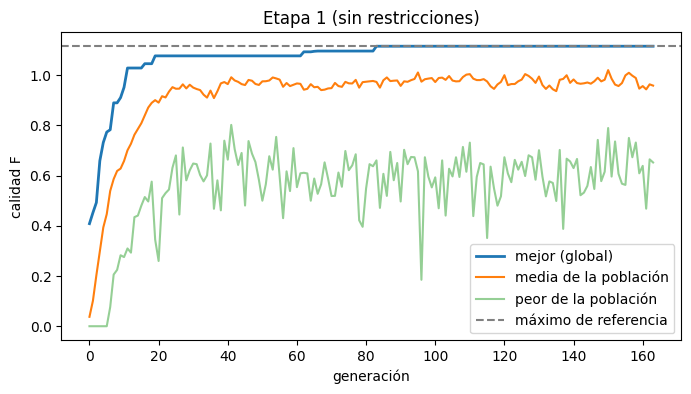

gen   0: mejor 0.4085 | media 0.0375 | cubiertas 1.0
gen  10: mejor 0.9517 | media 0.6581 | cubiertas 4.0
gen  25: mejor 1.0769 | media 0.9460 | cubiertas 5.0
gen  50: mejor 1.0769 | media 0.9755 | cubiertas 5.0
gen 163: mejor 1.1154 | media 0.9585 | cubiertas 6.0


In [52]:
import matplotlib.pyplot as plt


def graficar_evolucion(res, titulo=None, ax=None):
    h = res["historial"]
    ax = ax or plt.subplots(figsize=(8, 4))[1]
    ax.plot(h["generacion"], h["mejor_global"], label="mejor (global)", lw=2)
    ax.plot(h["generacion"], h["media"], label="media de la población")
    ax.plot(h["generacion"], h["peor"], label="peor de la población", alpha=0.5)
    ax.axhline(calidad_maxima_teorica(res["escenario"]), ls="--", c="gray", label="máximo de referencia")
    ax.set_xlabel("generación")
    ax.set_ylabel("calidad F")
    ax.set_title(titulo or res["escenario"].nombre)
    ax.legend(loc="lower right")
    return ax


graficar_evolucion(res_etapa1)
plt.show()

h1 = res_etapa1["historial"]
for g in [0, 10, 25, 50, int(h1["generacion"].max())]:
    fila = h1[h1["generacion"] == g]
    if len(fila):
        f = fila.iloc[0]
        print(f"gen {g:>3}: mejor {f['mejor_global']:.4f} | media {f['media']:.4f} | cubiertas {f['cubiertas_mejor_global']}")

**Interpretación.** La celda siguiente comprueba los criterios de §1.8 que aplican sin restricciones. Se imprimen como OK o FALLA en lugar de detener el notebook, porque un resultado desfavorable también es evidencia que hay que analizar.

In [53]:
def verificar_criterios(res):
    ev = res["mejor"]["eval"]
    det = cobertura_por_region(res["mejor"]["config"], res["escenario"])
    altas = det[det["prioridad"] == "Alta"]
    criterios = {
        "6 regiones cubiertas": ev["cubiertas"] == len(res["escenario"].regiones),
        "regiones Alta con redundancia (d ≥ 0.9)": bool((altas["d"] >= 0.9).all()),
        "violación 0": ev["violacion"] == 0,
        "calidad ≥ 98 % de la referencia": ev["fitness"] >= 0.98 * calidad_maxima_teorica(res["escenario"]),
        "la calidad mejoró respecto a la generación 0": ev["fitness"] > res["inicial"]["eval"]["fitness"],
    }
    for nombre, ok in criterios.items():
        print(f"[{'OK' if ok else 'FALLA'}] {nombre}")
    return criterios


_ = verificar_criterios(res_etapa1)

[OK] 6 regiones cubiertas
[OK] regiones Alta con redundancia (d ≥ 0.9)
[OK] violación 0
[OK] calidad ≥ 98 % de la referencia
[OK] la calidad mejoró respecto a la generación 0


## §7. Restricciones espaciales

Las zonas de desechos (3.1) y las posiciones ocupadas (3.2) se interpretan como **círculos sobre la esfera** con el radio angular que da el enunciado: un satélite no puede tener su punto subsatélite a menos de esa distancia del centro. Se agrega la separación mínima de 1° entre satélites (§1.5).

Las restricciones actúan en tres puntos del algoritmo, no solo en el dibujo:

1. **Evaluación** (`evaluar_con_restricciones`): calcula la calidad y la **violación**, la suma de grados que cada satélite invade cada zona más lo que le falta a cada pareja de satélites para separarse 1°.
2. **Comparación** (`clave_deb`, regla de Deb): una configuración válida siempre es mejor que una inválida; entre inválidas gana la de menor violación; entre válidas, la de mayor calidad. Así una configuración con mucha cobertura pero inválida nunca puede ser la respuesta.
3. **Generación** (`inicializar_factible` y `reparar`): la población inicial solo tiene posiciones válidas (muestreo con rechazo), y si una mutación deja un satélite en zona prohibida, se busca una posición válida cerca. Si no existe ninguna, el satélite se queda donde está y la configuración sigue marcada como inválida.

In [54]:
def _zonas_arreglos(esc):
    if not esc.zonas:
        return np.empty(0), np.empty(0), np.empty(0)
    z = np.array([[z.lat, z.lon, z.radio_deg] for z in esc.zonas])
    return z[:, 0], z[:, 1], z[:, 2]


def violacion_total(config, esc):
    c = np.asarray(config, dtype=float)
    zlat, zlon, zrad = _zonas_arreglos(esc)
    total = 0.0
    if len(zrad):
        d = distancia_angular(zlat[:, None], zlon[:, None], c[None, :, 0], c[None, :, 1])
        total += np.maximum(0.0, zrad[:, None] - d).sum()
    ds = distancia_angular(c[:, None, 0], c[:, None, 1], c[None, :, 0], c[None, :, 1])
    iu = np.triu_indices(len(c), k=1)
    total += np.maximum(0.0, esc.separacion_min_deg - ds[iu]).sum()
    return float(total)


def punto_valido(p, esc, otros):
    zlat, zlon, zrad = _zonas_arreglos(esc)
    if len(zrad) and np.any(distancia_angular(zlat, zlon, p[0], p[1]) < zrad):
        return False
    if len(otros) and np.any(distancia_angular(otros[:, 0], otros[:, 1], p[0], p[1]) < esc.separacion_min_deg):
        return False
    return True


def evaluar_con_restricciones(config, esc):
    ev = evaluar_calidad(config, esc)
    ev["violacion"] = violacion_total(config, esc)
    return ev


def clave_deb(ev):
    return (ev["violacion"] == 0, -ev["violacion"], ev["fitness"])


def inicializar_factible(rng, esc, n, intentos=500):
    """Cada satélite se sortea hasta caer en una posición válida (o se agotan los intentos)."""
    poblacion = []
    for _ in range(n):
        ind = []
        for _ in range(esc.n_satelites):
            otros = np.array(ind) if ind else np.empty((0, 2))
            for _ in range(intentos):
                p = posiciones_aleatorias(rng, 1)[0]
                if punto_valido(p, esc, otros):
                    break
            ind.append(p)
        poblacion.append(np.array(ind))
    return np.array(poblacion)


def reparar(rng, config, esc, intentos=60):
    """Mueve cada satélite inválido a la posición válida más cercana que encuentre."""
    c = np.asarray(config, dtype=float).copy()
    for i in range(len(c)):
        otros = np.delete(c, i, axis=0)
        if punto_valido(c[i], esc, otros):
            continue
        escala_lon = 1.0 / max(math.cos(math.radians(c[i, 0])), 0.2)
        for k in range(intentos):  # búsqueda local con radio creciente
            sigma = 1.0 + 0.5 * k
            cand = normalizar(c[i] + rng.normal(0, sigma, 2) * [1.0, escala_lon])
            if punto_valido(cand, esc, otros):
                c[i] = cand
                break
        else:  # sin éxito cerca: cualquier posición válida del globo
            for _ in range(intentos):
                cand = posiciones_aleatorias(rng, 1)[0]
                if punto_valido(cand, esc, otros):
                    c[i] = cand
                    break
    return c


def evolucionar_con_restricciones(esc, params):
    return evolucionar(esc, params, evaluar=evaluar_con_restricciones, inicializar=inicializar_factible,
                       reparar=reparar, clave=clave_deb)


def detalle_restricciones(config, esc):
    """Para cada zona: distancia del satélite más cercano y si alguno la invade."""
    c = np.asarray(config, dtype=float)
    filas = []
    for z in esc.zonas:
        d = distancia_angular(z.lat, z.lon, c[:, 0], c[:, 1])
        filas.append({"zona": z.nombre, "tipo": z.tipo, "radio": z.radio_deg, "sat_mas_cercano": int(d.argmin()),
                      "distancia_min": float(d.min()), "margen": float(d.min() - z.radio_deg),
                      "invadida": bool(d.min() < z.radio_deg)})
    ds = distancia_angular(c[:, None, 0], c[:, None, 1], c[None, :, 0], c[None, :, 1])
    np.fill_diagonal(ds, np.inf)
    filas.append({"zona": "separación entre satélites", "tipo": "propia", "radio": esc.separacion_min_deg,
                  "sat_mas_cercano": int(np.unravel_index(ds.argmin(), ds.shape)[0]), "distancia_min": float(ds.min()),
                  "margen": float(ds.min() - esc.separacion_min_deg), "invadida": bool(ds.min() < esc.separacion_min_deg)})
    return pd.DataFrame(filas)


# Pruebas de las funciones de restricción
_esc = escenario_base()
_atl = ZONAS_BASE[0]
assert not punto_valido(np.array([_atl.lat, _atl.lon]), _esc, np.empty((0, 2)))
assert punto_valido(np.array(destino(_atl.lat, _atl.lon, _atl.radio_deg + 0.1, 0)), _esc, np.empty((0, 2)))
_c = np.array(ideal)
assert violacion_total(_c, _esc) == 0
_c[0] = [_atl.lat, _atl.lon]  # un satélite justo en el centro del Atlántico Norte
assert abs(violacion_total(_c, _esc) - _atl.radio_deg) < 1e-9
assert violacion_total(reparar(np.random.default_rng(0), _c, _esc), _esc) == 0
assert clave_deb({"violacion": 0.0, "fitness": 0.1}) > clave_deb({"violacion": 0.5, "fitness": 1.1})
print("Pruebas de restricciones: OK")

Pruebas de restricciones: OK


## §8. Etapa 2: búsqueda con restricciones

Mismo escenario, parámetros y semilla que la etapa 1, ahora con las tres zonas de desechos y los dos objetos. Primero se revisa si la solución de la etapa 1 habría sido aceptable con las restricciones; después se ejecuta el algoritmo con ellas.

In [55]:
esc_base = escenario_base()
ev_e1 = evaluar_con_restricciones(res_etapa1["mejor"]["config"], esc_base)
print(f"La solución de la etapa 1 bajo las restricciones: violación {ev_e1['violacion']:.3f} -> "
      f"{'válida' if ev_e1['violacion'] == 0 else 'INVÁLIDA'}")

res_etapa2 = evolucionar_con_restricciones(esc_base, ParametrosGA(semilla=42))
resumen_resultado(res_etapa2)
cobertura_por_region(res_etapa2["mejor"]["config"], esc_base).round(3)

La solución de la etapa 1 bajo las restricciones: violación 0.000 -> válida
Escenario: Base
Evaluaciones: 9674 | parada: estancamiento (80 generaciones sin mejora) | mejor encontrado en la generación 43
Calidad: inicial 0.2723 -> final 1.0962 (referencia 1.1154, 98.3 %)
Regiones cubiertas: inicial 1 -> final 6 de 6
Violación de restricciones: 0.000


,region,prioridad,f,d,cubierta,dist_sat_mas_cercano
0,Península de Yucatán,Alta,1.0,1.0,True,2.881
1,Amazonía brasileña,Alta,1.0,0.0,True,3.073
2,California,Media,1.0,0.0,True,2.731
3,Sahel,Media,1.0,0.0,True,2.609
4,Japón,Media,1.0,1.0,True,4.133
5,Interior de Australia,Normal,1.0,0.0,True,3.059


In [56]:
detalle_restricciones(res_etapa2["mejor"]["config"], esc_base).round(2)

,zona,tipo,radio,sat_mas_cercano,distancia_min,margen,invadida
0,Atlántico Norte,desechos,12.0,2,42.44,30.44,False
1,Pacífico Sur,desechos,10.0,0,58.81,48.81,False
2,Región polar norte,desechos,8.0,3,58.58,50.58,False
3,Objeto A,ocupada,5.0,2,41.93,36.93,False
4,Objeto B,ocupada,5.0,4,26.64,21.64,False
5,separación entre satélites,propia,1.0,0,3.26,2.26,False


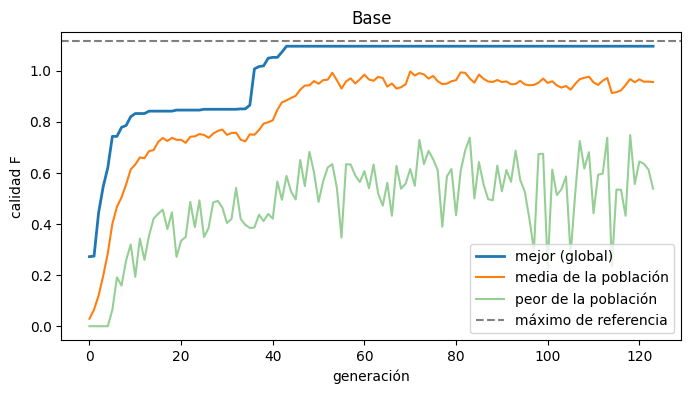

[OK] 6 regiones cubiertas
[FALLA] regiones Alta con redundancia (d ≥ 0.9)
[OK] violación 0
[OK] calidad ≥ 98 % de la referencia
[OK] la calidad mejoró respecto a la generación 0
Individuos válidos por generación: mínimo 80 de 80


In [57]:
graficar_evolucion(res_etapa2)
plt.show()
_ = verificar_criterios(res_etapa2)
print(f"Individuos válidos por generación: mínimo {res_etapa2['historial']['validos'].min()} de {res_etapa2['params'].poblacion}")

**Interpretación.** En el escenario base las zonas prohibidas no están encima de ninguna región, así que las restricciones casi no reducen la calidad alcanzable: la referencia teórica sigue siendo la misma. Lo que sí garantizan es que la respuesta no pueda tener satélites en zonas prohibidas, aunque fueran útiles. Las pruebas de §10 fuerzan casos donde las restricciones sí cuestan cobertura.

## §9. Cambio de condiciones (3.3)

`reevaluar` toma una configuración ya obtenida y la evalúa en un escenario modificado, sin volver a evolucionar. Responde si la configuración anterior sigue siendo válida y cuánto cambia su calidad. Después se vuelve a ejecutar el algoritmo en el escenario nuevo para comparar.

In [58]:
def reevaluar(config, esc_nuevo, etiqueta=""):
    ev = evaluar_con_restricciones(config, esc_nuevo)
    det = detalle_restricciones(config, esc_nuevo)
    invadidas = det.loc[det["invadida"], "zona"].tolist()
    print(f"{etiqueta}: {'VÁLIDA' if ev['violacion'] == 0 else 'INVÁLIDA'} | calidad {ev['fitness']:.4f} | "
          f"cubiertas {ev['cubiertas']} | zonas invadidas: {invadidas or 'ninguna'}")
    return ev


def comparar_antes_despues(config_anterior, esc_nuevo, semilla=42):
    ev_ant = reevaluar(config_anterior, esc_nuevo, "Configuración anterior en el escenario nuevo")
    res = evolucionar_con_restricciones(esc_nuevo, ParametrosGA(semilla=semilla))
    ev_new = reevaluar(res["mejor"]["config"], esc_nuevo, "Configuración re-evolucionada")
    print(f"Referencia teórica del escenario nuevo: {calidad_maxima_teorica(esc_nuevo):.4f}")
    return ev_ant, res


config_e2 = res_etapa2["mejor"]["config"]

# Cambio A: California pasa de prioridad Media a Alta
esc_california = replace(esc_base, nombre="California con prioridad Alta",
                         regiones=[replace(r, prioridad="Alta") if r.nombre == "California" else r for r in esc_base.regiones])
print("== Cambio A: California con prioridad Alta ==")
ev_a, res_cambio_a = comparar_antes_despues(config_e2, esc_california)
cobertura_por_region(res_cambio_a["mejor"]["config"], esc_california)[["region", "prioridad", "f", "d"]].round(2)

== Cambio A: California con prioridad Alta ==
Configuración anterior en el escenario nuevo: VÁLIDA | calidad 1.0893 | cubiertas 6 | zonas invadidas: ninguna
Configuración re-evolucionada: VÁLIDA | calidad 1.1071 | cubiertas 6 | zonas invadidas: ninguna
Referencia teórica del escenario nuevo: 1.1071


,region,prioridad,f,d
0,Península de Yucatán,Alta,1.0,0.0
1,Amazonía brasileña,Alta,1.0,1.0
2,California,Alta,1.0,1.0
3,Sahel,Media,1.0,0.0
4,Japón,Media,1.0,0.0
5,Interior de Australia,Normal,1.0,0.0


In [59]:
# Cambio B: una zona nueva deja de estar disponible justo donde hoy hay un satélite (el más cercano a Japón)
japon = next(r for r in esc_base.regiones if r.nombre == "Japón")
i_jp = int(distancia_angular(japon.lat, japon.lon, config_e2[:, 0], config_e2[:, 1]).argmin())
zona_nueva = Zona("Zona nueva (desechos)", float(config_e2[i_jp, 0]), float(config_e2[i_jp, 1]), 3.0, "desechos")
esc_zona_nueva = replace(esc_base, nombre="Zona nueva sobre un satélite", zonas=esc_base.zonas + [zona_nueva])
print(f"== Cambio B: zona de 3° centrada en el satélite {i_jp} ({zona_nueva.lat:.2f}, {zona_nueva.lon:.2f}) ==")
ev_b, res_cambio_b = comparar_antes_despues(config_e2, esc_zona_nueva)
assert ev_b["violacion"] > 0, "la configuración anterior debía quedar inválida"
assert res_cambio_b["mejor"]["eval"]["violacion"] == 0
cobertura_por_region(res_cambio_b["mejor"]["config"], esc_zona_nueva)[["region", "f", "d", "cubierta"]].round(2)

== Cambio B: zona de 3° centrada en el satélite 3 (34.93, 133.10) ==
Configuración anterior en el escenario nuevo: INVÁLIDA | calidad 1.0962 | cubiertas 6 | zonas invadidas: ['Zona nueva (desechos)']
Configuración re-evolucionada: VÁLIDA | calidad 1.0962 | cubiertas 6 | zonas invadidas: ninguna
Referencia teórica del escenario nuevo: 1.1154


,region,f,d,cubierta
0,Península de Yucatán,1.0,0.0,True
1,Amazonía brasileña,1.0,1.0,True
2,California,1.0,0.0,True
3,Sahel,1.0,0.0,True
4,Japón,1.0,1.0,True
5,Interior de Australia,1.0,0.0,True


**Interpretación.** Cambiar una prioridad no invalida una configuración: solo cambia cuánto vale, porque las restricciones son las mismas. Agregar una zona sí puede invalidarla si la zona cae sobre un satélite; en ese caso el sistema lo detecta (violación > 0, zona invadida) y la re-evolución encuentra una configuración válida que sustituye a la anterior.

## §10. Pruebas de restricciones

Cada prueba indica condiciones, resultado e interpretación. Las comprobaciones que deben cumplirse siempre usan `assert`.

### Prueba: zonas restringidas por desechos

Condiciones: escenario base, semilla 42. Se revisa la solución final, la población completa de cada generación, y una configuración sembrada a propósito dentro de cada zona.

In [60]:
det2 = detalle_restricciones(config_e2, esc_base)
assert not det2["invadida"].any(), "la solución final invade una zona"
print("Margen de la solución final a cada zona de desechos (grados fuera del radio):")
print(det2[det2["tipo"] == "desechos"][["zona", "radio", "distancia_min", "margen"]].round(2).to_string(index=False))

for z in [z for z in esc_base.zonas if z.tipo == "desechos"]:
    sembrada = np.array(ideal)
    sembrada[7] = [z.lat, z.lon]
    ev = evaluar_con_restricciones(sembrada, esc_base)
    reparada = reparar(np.random.default_rng(1), sembrada, esc_base)
    assert ev["violacion"] > 0 and violacion_total(reparada, esc_base) == 0
    print(f"{z.nombre}: satélite sembrado en el centro -> violación {ev['violacion']:.2f}°; "
          f"reparado a {distancia_angular(z.lat, z.lon, *reparada[7]):.2f}° del centro (radio {z.radio_deg}°)")

Margen de la solución final a cada zona de desechos (grados fuera del radio):
              zona  radio  distancia_min  margen
   Atlántico Norte   12.0          42.44   30.44
      Pacífico Sur   10.0          58.81   48.81
Región polar norte    8.0          58.58   50.58
Atlántico Norte: satélite sembrado en el centro -> violación 12.00°; reparado a 24.20° del centro (radio 12.0°)
Pacífico Sur: satélite sembrado en el centro -> violación 10.00°; reparado a 10.81° del centro (radio 10.0°)
Región polar norte: satélite sembrado en el centro -> violación 8.00°; reparado a 9.13° del centro (radio 8.0°)


### Prueba: posiciones ocupadas

Condiciones: objetos A y B con radio de exclusión de 5°. Además del satélite en el centro, se prueban posiciones justo dentro (4.9°) y justo fuera (5.1°) del radio para comprobar el límite.

In [61]:
for z in [z for z in esc_base.zonas if z.tipo == "ocupada"]:
    dentro = np.array(destino(z.lat, z.lon, 4.9, 45))
    fuera = np.array(destino(z.lat, z.lon, 5.1, 45))
    assert not punto_valido(np.array([z.lat, z.lon]), esc_base, np.empty((0, 2)))
    assert not punto_valido(dentro, esc_base, np.empty((0, 2)))
    assert punto_valido(fuera, esc_base, np.empty((0, 2)))
    margen = det2.loc[det2["zona"] == z.nombre, "margen"].iloc[0]
    print(f"{z.nombre}: centro y 4.9° rechazados, 5.1° aceptado; margen de la solución final {margen:.2f}°")

Objeto A: centro y 4.9° rechazados, 5.1° aceptado; margen de la solución final 36.93°
Objeto B: centro y 4.9° rechazados, 5.1° aceptado; margen de la solución final 21.64°


### Prueba: espacio reducido

Condiciones: todos los radios de exclusión ×1.5 y una zona extra de 4° centrada en la Amazonía. Para cubrir la Amazonía por completo un satélite debe estar a menos de ≈ 4.4° de su centro, así que la zona extra deja un anillo estrecho donde colocarlo.

In [62]:
zonas_reducidas = [replace(z, radio_deg=z.radio_deg * 1.5) for z in esc_base.zonas]
zonas_reducidas.append(Zona("Zona extra Amazonía", -3.5, -62.0, 4.0, "desechos"))
esc_reducido = replace(esc_base, nombre="Espacio reducido", zonas=zonas_reducidas)

reevaluar(config_e2, esc_reducido, "Solución de la etapa 2 en el espacio reducido")
res_reducido = evolucionar_con_restricciones(esc_reducido, ParametrosGA(semilla=42))
resumen_resultado(res_reducido)
comparacion = cobertura_por_region(config_e2, esc_base)[["region", "f", "d"]].merge(
    cobertura_por_region(res_reducido["mejor"]["config"], esc_reducido)[["region", "f", "d"]],
    on="region", suffixes=(" base", " reducido"))
assert res_reducido["mejor"]["eval"]["violacion"] == 0
comparacion.round(2)

Solución de la etapa 2 en el espacio reducido: INVÁLIDA | calidad 1.0962 | cubiertas 6 | zonas invadidas: ['Zona extra Amazonía']
Escenario: Espacio reducido
Evaluaciones: 10220 | parada: estancamiento (80 generaciones sin mejora) | mejor encontrado en la generación 50
Calidad: inicial 0.2723 -> final 1.0962 (referencia 1.1154, 98.3 %)
Regiones cubiertas: inicial 1 -> final 6 de 6
Violación de restricciones: 0.000


,region,f base,d base,f reducido,d reducido
0,Península de Yucatán,1.0,1.0,1.0,0.0
1,Amazonía brasileña,1.0,0.0,1.0,1.0
2,California,1.0,0.0,1.0,0.0
3,Sahel,1.0,0.0,1.0,1.0
4,Japón,1.0,1.0,1.0,0.0
5,Interior de Australia,1.0,0.0,1.0,0.0


**Interpretación.** La tabla compara región por región la cobertura con el espacio base y con el reducido. Si la Amazonía pierde redundancia o cobertura, es efecto directo de la zona extra: la restricción cambia la solución, no solo el dibujo.

### Prueba: condición difícil o inviable

Dos casos:

- **(a) Región imposible de cubrir.** Una zona centrada en Yucatán con radio mayor que ρ + 2.7°. Todo punto desde el que se podría observar alguna parte de Yucatán queda dentro de la zona, así que ninguna configuración válida puede cubrirla. El sistema debe detectarlo antes de evolucionar y devolver la mejor configuración válida para las demás regiones.
- **(b) Ninguna configuración válida.** Dos zonas que cubren todo el globo. No existe ninguna posición válida; el sistema debe decirlo y no devolver una configuración inválida como si fuera solución.

In [63]:
def regiones_inalcanzables(esc):
    """Regiones cuyo disco de posiciones útiles (radio ρ + radio de la región) cae entero dentro de una zona."""
    rho = radio_huella_deg(esc.altura_km, esc.elevacion_min_deg)
    salida = []
    for r in esc.regiones:
        alcance = rho + km_a_grados(r.radio_km)
        for z in esc.zonas:
            if distancia_angular(z.lat, z.lon, r.lat, r.lon) + alcance <= z.radio_deg:
                salida.append((r.nombre, z.nombre))
                break
    return salida


def calidad_maxima_alcanzable(esc):
    """Como calidad_maxima_teorica, pero sin contar las regiones inalcanzables."""
    fuera = {n for n, _ in regiones_inalcanzables(esc)}
    w_tot = esc.pesos().sum()
    w = np.sort([PESOS_PRIORIDAD[r.prioridad] for r in esc.regiones if r.nombre not in fuera])[::-1]
    sobrantes = max(0, esc.n_satelites - len(w))
    return (w.sum() + esc.beta_redundancia * w[:sobrantes].sum()) / w_tot


def informe_factibilidad(res):
    ev = res["mejor"]["eval"]
    if ev["violacion"] > 0:
        print(f"SIN SOLUCIÓN VÁLIDA: ninguna de las {res['evaluaciones']} configuraciones evaluadas cumple las restricciones. "
              f"La menos mala invade {ev['violacion']:.1f}° en total; no debe usarse.")
        return False
    print(f"Solución válida: calidad {ev['fitness']:.4f}, máximo alcanzable {calidad_maxima_alcanzable(res['escenario']):.4f}, "
          f"cubiertas {ev['cubiertas']} de {len(res['escenario'].regiones)}")
    return True


radio_bloqueo = RHO + km_a_grados(300) + 0.5
esc_bloqueo = replace(esc_base, nombre="Yucatán bloqueada",
                      zonas=esc_base.zonas + [Zona("Bloqueo Yucatán", 20.5, -89.0, radio_bloqueo, "desechos")])
print(f"(a) Zona de {radio_bloqueo:.2f}° sobre Yucatán. Regiones inalcanzables detectadas: {regiones_inalcanzables(esc_bloqueo)}")
res_bloqueo = evolucionar_con_restricciones(esc_bloqueo, ParametrosGA(semilla=42))
informe_factibilidad(res_bloqueo)
cob_bloqueo = cobertura_por_region(res_bloqueo["mejor"]["config"], esc_bloqueo)
assert res_bloqueo["mejor"]["eval"]["violacion"] == 0
assert cob_bloqueo.loc[cob_bloqueo["region"] == "Península de Yucatán", "f"].iloc[0] == 0
cob_bloqueo[["region", "prioridad", "f", "d", "cubierta"]].round(2)

(a) Zona de 10.33° sobre Yucatán. Regiones inalcanzables detectadas: [('Península de Yucatán', 'Bloqueo Yucatán')]
Solución válida: calidad 0.9038, máximo alcanzable 0.9038, cubiertas 5 de 6


,region,prioridad,f,d,cubierta
0,Península de Yucatán,Alta,0.0,0.0,False
1,Amazonía brasileña,Alta,1.0,1.0,True
2,California,Media,1.0,0.0,True
3,Sahel,Media,1.0,1.0,True
4,Japón,Media,1.0,1.0,True
5,Interior de Australia,Normal,1.0,0.0,True


In [64]:
esc_imposible = replace(esc_base, nombre="Todo el globo prohibido",
                        zonas=[Zona("Hemisferio norte+", 90, 0, 91, "desechos"), Zona("Hemisferio sur+", -90, 0, 91, "desechos")])
res_imposible = evolucionar_con_restricciones(esc_imposible, ParametrosGA(semilla=42, poblacion=30, generaciones=30, paciencia=10))
print("(b)", end=" ")
assert informe_factibilidad(res_imposible) is False
print(f"Individuos válidos en todas las generaciones: {res_imposible['historial']['validos'].max()}")

(b) SIN SOLUCIÓN VÁLIDA: ninguna de las 870 configuraciones evaluadas cumple las restricciones. La menos mala invade 18.0° en total; no debe usarse.
Individuos válidos en todas las generaciones: 0


**Interpretación.** En (a) el sistema identifica de antemano qué región no se puede cubrir y por qué (qué zona la bloquea), y el algoritmo reparte los satélites entre las demás regiones sin violar ninguna restricción. La calidad se compara contra el máximo **alcanzable**, no contra el teórico, porque ninguna configuración válida puede recuperar la región bloqueada. En (b) no hay ninguna configuración válida: el sistema lo reporta explícitamente en lugar de entregar la configuración menos mala como si fuera una solución.


## §11. Globo 3D (Entregable 5)

Página interactiva generada con los resultados del algoritmo: globo 3D que se gira, mapa 2D y curva de calidad.

- Regiones = verde (relleno si está cubierta, punteado si no)
- Zonas de desechos = rojo
- Posiciones ocupadas = naranja
- Satélites = azul, con su huella en azul claro
- Botones Inicial / Final para comparar la generación 0 con la final

In [65]:
##§11 · Código A: contornos del mundo

In [66]:
import json

MUNDO = json.loads('{"tierra":[{"p":[[-168,66],[-162,70],[-156,71.5],[-141,69.5],[-128,70],[-115,68.5],[-95,68],[-85,69.5],[-82,66],[-88,64],[-94,59],[-92,57],[-82,55],[-80,51],[-78,56],[-77,60.5],[-70,59],[-65,60],[-61,56],[-56,52],[-59,48],[-66,45],[-70,43.5],[-70.5,41.5],[-74,40.5],[-76,38],[-75.5,35.5],[-79,33],[-81,31],[-80,27],[-80.5,25],[-82,26.5],[-83,29.5],[-85,30],[-89,30],[-90.5,29],[-94,29.5],[-97.5,27.5],[-97.5,24],[-98,22],[-96.5,19.5],[-94.5,18],[-91.5,18.5],[-90.5,21],[-87,21.5],[-87.5,18.5],[-88.5,16],[-84,16],[-83.5,12],[-83.5,11],[-81.5,9],[-79.5,9.5],[-77.5,8.5],[-78,7],[-80,7.5],[-80.5,8.5],[-83.5,8.5],[-86,10],[-87.5,13],[-91.5,14],[-94,16],[-96.5,15.5],[-99.5,16.5],[-103.5,18.5],[-105.5,20.5],[-105.5,23],[-108.5,25.5],[-111,28],[-113,31.5],[-115,32],[-113,29],[-111.5,26],[-110,23],[-112,25],[-114,28],[-116,30.5],[-117,32.5],[-118.5,34],[-120.5,34.5],[-122.5,37.5],[-124,40.5],[-124.5,43],[-124,46.5],[-124.5,48.5],[-123,49],[-127,50.5],[-130,54.5],[-133,57],[-136,58.5],[-140,59.5],[-146,60.5],[-151,59.5],[-154,57.5],[-158,56.5],[-162,55],[-164,54.5],[-159,58],[-162,58.5],[-165,60.5],[-165,62.5],[-164.5,63],[-161,64.5],[-166,64.5],[-168,65.5]],"hielo":false},{"p":[[-73,78],[-66,81],[-45,82.5],[-25,83],[-20,81],[-18,77],[-20,73],[-22,70],[-26,68.5],[-33,67.5],[-40,65],[-43,60],[-47,61],[-50,64],[-52,67],[-54,70],[-56,73],[-61,76],[-68,76.5]],"hielo":true},{"p":[[-80,73.5],[-72,71.5],[-67,69],[-62,66.5],[-64,63],[-70,62.5],[-74,64.5],[-79,64],[-78,67],[-82,69.5],[-88,70.5],[-85,73]],"hielo":false},{"p":[[-90,76.5],[-80,76.5],[-75,78.5],[-65,81],[-62,82.5],[-75,83],[-90,81],[-95,78.5]],"hielo":false},{"p":[[-118,71.5],[-110,73],[-102,73],[-101,70],[-106,68.5],[-113,68.5],[-118,69]],"hielo":false},{"p":[[-92,76.5],[-80,76],[-80,74.5],[-91,74.5]],"hielo":false},{"p":[[-125,72],[-120,74],[-116,73.5],[-118,71.5],[-123,71]],"hielo":false},{"p":[[-59.5,47.5],[-56,51.5],[-55.5,49.5],[-53.5,48],[-52.5,47.5],[-53.5,46.5],[-56,47],[-59,47.5]],"hielo":false},{"p":[[-85,22],[-82,23],[-77.5,22],[-74,20],[-77.5,20],[-78.5,21.5],[-81.5,22],[-83.5,22]],"hielo":false},{"p":[[-74.5,18.5],[-73,20],[-69.5,19.5],[-68.5,18.5],[-71.5,17.5],[-73,18]],"hielo":false},{"p":[[-78.5,18.5],[-76.5,18],[-77,18],[-78,18]],"hielo":false},{"p":[[-67,18.5],[-65.5,18.5],[-66,18],[-67,18]],"hielo":false},{"p":[[-77.5,8.5],[-75.5,11],[-71.5,12.5],[-68,10.5],[-63,10.5],[-60.5,8.5],[-57,6],[-52,5],[-50,2],[-48.5,-1],[-44.5,-2.5],[-39,-3.5],[-35,-5.5],[-35,-7.5],[-37,-11],[-39,-13.5],[-39,-18],[-40.5,-21],[-42,-23],[-44.5,-23.5],[-48.5,-26],[-49,-28.5],[-51,-31],[-53.5,-34],[-56,-35],[-58.5,-34],[-57,-36.5],[-57.5,-38],[-62,-39],[-62.5,-40.5],[-65,-41],[-64,-42.5],[-65.5,-45],[-67.5,-46.5],[-66,-48],[-68.5,-50.5],[-69,-52],[-68.5,-54.5],[-66,-55],[-71,-55.5],[-74.5,-52.5],[-75.5,-48],[-74,-43.5],[-73.5,-40],[-73.5,-37],[-71.5,-32],[-71.5,-28],[-70.5,-23],[-70,-18.5],[-72,-17],[-76,-14],[-77.5,-11],[-79.5,-7.5],[-81,-5.5],[-80,-3],[-80.5,-1],[-80,1],[-78.5,2],[-77.5,4],[-77.5,7]],"hielo":false},{"p":[[-61.5,-52],[-58,-51.5],[-58.5,-52.5],[-60.5,-52.5]],"hielo":false},{"p":[[-9,43],[-9.5,39],[-9,37],[-6,36],[-5.5,36],[-2,36.5],[0,38.5],[0.5,40.5],[3,42],[4,43.5],[6.5,43],[8.5,44.5],[10.5,43.5],[12.5,42],[15.5,40],[15.5,38],[17,39],[18.5,40],[17,41],[16,42],[14,42.5],[12.5,44.5],[12.5,45.5],[13.5,45.5],[15,44.5],[17,43],[19.5,42],[19.5,40],[21,38],[22.5,36.5],[23,38],[24,38],[23,39.5],[24,41],[26,41],[26,40.5],[26.5,38.5],[27.5,37],[28.5,36.5],[30.5,36.5],[32.5,36],[34.5,37],[36,37],[36,35.5],[35,33],[34.5,31.5],[32.5,31],[32.5,30],[34,28],[35,29.5],[35,28],[37,25],[39,21.5],[41,18],[43,15],[43.5,12.5],[45,13],[48.5,14],[52,15.5],[55,17.5],[57,19],[58.5,20.5],[60,22.5],[58.5,23.5],[56.5,25],[56.5,26],[55.5,25.5],[54,24],[51.5,24.5],[51,26],[50,26.5],[48.5,28.5],[48,30],[49.5,30],[50.5,29],[51.5,28],[54,26.5],[56.5,27],[57.5,25.5],[61.5,25],[66.5,25.5],[67.5,24],[68.5,23.5],[70,22.5],[73,21],[73,19],[73.5,16],[74.5,13.5],[76,11],[77.5,8],[78,9],[79.5,10.5],[80,12],[80.5,15.5],[82.5,17],[85,19],[87,21.5],[88.5,22],[90.5,22.5],[92,22.5],[92.5,21],[94,19],[94.5,16],[97.5,17],[98,14.5],[98.5,12.5],[98.5,9],[98.5,8],[100.5,6],[100.5,3.5],[101.5,3],[103.5,1.5],[104,1.5],[103.5,4],[102,6],[101,7],[100,8.5],[99,9.5],[99.5,11.5],[100,13.5],[101,12.5],[102.5,12],[103,11],[105,8.5],[106.5,10.5],[109,11.5],[109,13],[109,15.5],[106.5,17.5],[105.5,19],[106.5,20.5],[108,21.5],[110,21.5],[110.5,20.5],[111,21.5],[113.5,22.5],[116.5,23],[118.5,24.5],[120,26],[120.5,28],[122,31],[121,32.5],[120.5,34.5],[119,35],[120.5,36],[122.5,37],[121,38],[119,37.5],[118,38.5],[117.5,39],[119.5,40],[121.5,41],[122,40.5],[121.5,39],[123,39.5],[124.5,40],[125.5,37.5],[126.5,37.5],[126.5,34.5],[127.5,34.5],[129.5,35],[129.5,37],[128.5,38.5],[127.5,40],[129.5,41],[130.5,42.5],[133,43],[135.5,44],[138,46.5],[140.5,48.5],[141.5,52],[140.5,53],[137,54],[135,54.5],[137,56.5],[140.5,58],[143.5,59.5],[148.5,59.5],[152,59],[155,59],[157,61.5],[160,62],[163.5,62.5],[163,61],[160,60],[158,58],[156,57],[156,53.5],[156.5,51],[158.5,52.5],[160,54],[162,56],[163.5,58],[162,58.5],[164,60],[166.5,60.5],[170.5,60],[172.5,61],[177.5,62.5],[179,62.5],[180,65],[180,69],[175,70],[170.5,70],[166,69.5],[161,69.5],[157,71],[152,71],[147,72.5],[140,72.5],[135.5,71.5],[130,71],[128.5,73],[126.5,73.5],[123.5,73.5],[118,73.5],[113,73.5],[110,74],[112.5,76.5],[107,77.5],[104.5,77.5],[100,76.5],[98,76],[94,76],[89,75.5],[86.5,74.5],[87,73.5],[80.5,73.5],[80.5,72],[78.5,72.5],[75.5,72.5],[75.5,71],[73,71.5],[72.5,73],[71,73],[68.5,73],[67,71.5],[66.5,69.5],[64,69.5],[60,69],[58,68.5],[54,68.5],[50,68],[46,68],[44,66.5],[41,66.5],[39.5,64.5],[36.5,65],[37,66],[41,67.5],[39.5,68],[33,69],[29,70],[25,71],[19,70],[15,68.5],[12.5,66],[10.5,64],[5,62.5],[5,60],[5.5,58.5],[7,58],[8.5,58.5],[10.5,59.5],[12,58.5],[12.5,56.5],[13,55.5],[14.5,55.5],[16,56],[16.5,57.5],[17,59],[18.5,59.5],[18,60.5],[17.5,62.5],[19,63.5],[21.5,65],[22.5,66],[25.5,65],[25,64],[21.5,63],[21.5,61],[23,60],[25,60.5],[28,60.5],[30,60],[28,59.5],[24.5,59.5],[23.5,59],[23.5,58],[24.5,58.5],[24,57],[21.5,57],[21,56],[21,55],[20,54.5],[18.5,54.5],[16.5,54.5],[14,54],[12,54],[11,54.5],[10,55],[10.5,56],[10.5,57.5],[8,57],[8,55.5],[8.5,54],[7,53.5],[5,53.5],[4,52],[3.5,51.5],[1.5,51],[1.5,50],[0,49.5],[-1,49.5],[-1.5,48.5],[-4.5,48.5],[-4.5,48],[-2.5,47],[-1,46],[-1.5,43.5],[-4,43.5],[-8,43.5],[-9.5,43]],"hielo":false},{"p":[[-180,65],[-172.5,64.5],[-170,66],[-172,67],[-180,69]],"hielo":false},{"p":[[-5.5,50],[-3,50.5],[1.5,51],[1.5,52.5],[0.5,53.5],[-0.5,54.5],[-1.5,55.5],[-2,57],[-2,57.5],[-4,57.5],[-3,58.5],[-5,58.5],[-6,57.5],[-5.5,56.5],[-6,55.5],[-4.5,54.5],[-3,55],[-3,54],[-4.5,53.5],[-4.5,53],[-5,52],[-3,51.5],[-4,51]],"hielo":false},{"p":[[-6,52],[-6,54],[-6,55],[-7.5,55.5],[-8.5,55],[-10,54],[-10,53.5],[-10.5,52],[-9.5,51.5],[-8,51.5]],"hielo":false},{"p":[[-22.5,64],[-18,63.5],[-14.5,64.5],[-13.5,65],[-15,66.5],[-18,66],[-22.5,66.5],[-24,65.5],[-22,64.5]],"hielo":false},{"p":[[11,78.5],[16,80],[23,80.5],[27,80],[21,78],[16,76.5]],"hielo":false},{"p":[[52,71.5],[56,73.5],[58,75.5],[63,76.5],[68.5,77],[64,75],[59,73],[56.5,71.5],[53.5,70.5]],"hielo":false},{"p":[[12.5,38],[15.5,38.5],[15,36.5]],"hielo":false},{"p":[[8.5,41],[10,41],[9.5,39],[8.5,39]],"hielo":false},{"p":[[80,10],[82,7.5],[81,6],[80,6],[80,8]],"hielo":false},{"p":[[108.5,19.5],[110,20],[111,19.5],[110.5,18.5],[109,18.5]],"hielo":false},{"p":[[121,25],[122,25],[121.5,23],[121,22],[120,23]],"hielo":false},{"p":[[131,34],[132.5,35.5],[135.5,35.5],[137,37],[138.5,38],[140,39.5],[140,41.5],[141.5,41.5],[142,39.5],[141,38],[141,37],[140.5,35],[139,35],[137,34.5],[135,33.5],[133,34],[131.5,34]],"hielo":false},{"p":[[130,33.5],[131.5,33.5],[131.5,32],[130.5,31],[130,32.5]],"hielo":false},{"p":[[140,41.5],[142,42.5],[143.5,42],[145.5,43.5],[144.5,44],[142,45.5],[141.5,43]],"hielo":false},{"p":[[132.5,33],[134.5,34],[133,33]],"hielo":false},{"p":[[142,46],[143.5,47],[143,49.5],[143,52],[142.5,54.5],[141.5,53],[142,51],[142,48.5]],"hielo":false},{"p":[[120.5,18.5],[122.5,18.5],[122,16.5],[121.5,14],[124,13],[123,13.5],[121,13.5],[120.5,14.5],[120,16]],"hielo":false},{"p":[[122,7],[123.5,8.5],[125.5,9.5],[126.5,7.5],[125.5,5.5],[124,6.5]],"hielo":false},{"p":[[124.5,12.5],[125.5,11.5],[125,10],[123.5,10],[123,11.5]],"hielo":false},{"p":[[95.5,5.5],[97.5,5],[100.5,2],[104,-1],[106,-3],[106,-6],[104.5,-6],[102.5,-4],[101,-2],[99,0.5],[98.5,2],[96,4]],"hielo":false},{"p":[[105,-7],[106,-6],[108.5,-6.5],[111,-6.5],[112.5,-7],[114.5,-8],[114.5,-8.5],[111,-8],[108,-8],[106.5,-7.5]],"hielo":false},{"p":[[109,1.5],[109.5,2],[111,2.5],[113,3],[114,4.5],[115.5,5.5],[117,7],[119,5.5],[118.5,4.5],[118,2],[119,1],[117.5,0],[116.5,-1.5],[116.5,-4],[114.5,-4],[113,-3.5],[111.5,-3],[110,-3],[110,-1.5],[109,-0.5]],"hielo":false},{"p":[[119.5,-5.5],[120.5,-5.5],[121,-2.5],[121.5,-4.5],[123,-5],[121.5,-2],[123.5,-1],[121.5,-1],[120.5,0.5],[122.5,1],[125,1.5],[124.5,0.5],[120,0.5],[120,-0.5],[119,-3],[119.5,-3.5]],"hielo":false},{"p":[[131,-1.5],[134,-1],[136,-2],[138,-1.5],[141,-2.5],[144,-4],[146,-5.5],[147.5,-6],[147,-8],[149.5,-9.5],[151,-10.5],[147.5,-10],[146,-8],[143.5,-9],[142.5,-9.5],[141,-9],[139,-8],[138,-8.5],[137.5,-7.5],[138.5,-7],[138.5,-5.5],[135,-4.5],[133.5,-4],[132,-3]],"hielo":false},{"p":[[113.5,-22],[114,-22],[116.5,-20.5],[121,-19.5],[122.5,-18],[123.5,-16.5],[125,-14.5],[127,-14],[128.5,-15],[129.5,-15],[130.5,-12.5],[132.5,-11.5],[136,-12],[136.5,-12],[136,-13.5],[135.5,-15],[137.5,-16.5],[139.5,-17.5],[141,-17.5],[141.5,-15],[141.5,-12.5],[142.5,-10.5],[143.5,-13],[144.5,-14.5],[145.5,-15],[146.5,-19],[149,-20.5],[150.5,-22.5],[153,-25],[153.5,-28.5],[153,-31],[151.5,-33.5],[150,-37.5],[147.5,-38],[146.5,-39],[145,-38],[143,-39],[140.5,-38],[139.5,-37.5],[138,-35.5],[138.5,-34],[138,-33],[137.5,-34.5],[136,-35],[135,-34.5],[134,-32.5],[131.5,-31.5],[128,-32],[125,-33],[123.5,-34],[120,-34],[118,-35],[115,-34.5],[115.5,-33.5],[115,-29.5],[114.5,-28.5],[113.5,-26],[114,-26.5],[113.5,-25],[114,-22.5]],"hielo":false},{"p":[[144.5,-40.5],[148.5,-41],[148,-43],[147,-43.5],[145.5,-42]],"hielo":false},{"p":[[172.5,-34.5],[174.5,-36],[176,-37.5],[178.5,-37.5],[178,-39],[177,-40],[175.5,-41.5],[174.5,-41],[175,-40],[174,-39],[174.5,-38],[174.5,-36.5]],"hielo":false},{"p":[[172.5,-40.5],[174.5,-41.5],[173,-43],[171,-44.5],[170.5,-46],[169,-46.5],[166.5,-46],[167,-44.5],[169,-44],[170.5,-42.5],[172,-41.5]],"hielo":false},{"p":[[32.5,31],[30,31.5],[25,32],[23,32.5],[20.5,32.5],[20,31],[18,31],[15.5,32],[13,33],[11,33.5],[10,34.5],[11,36],[10.5,37.5],[8.5,37],[5,37],[2,36.5],[-1,35.5],[-2.5,35],[-6,36],[-6.5,34],[-9.5,30.5],[-11,28],[-13.5,27.5],[-16,23.5],[-17,21],[-16.5,19.5],[-16.5,16],[-17.5,14.5],[-16.5,12.5],[-15,11],[-13.5,9.5],[-12.5,7.5],[-10.5,6],[-7.5,4.5],[-4,5],[-2,4.5],[1,6],[3,6.5],[4.5,6.5],[6,4.5],[7,4.5],[8.5,4.5],[9.5,3.5],[10,1],[9.5,-1],[12,-3.5],[12.5,-6],[13.5,-9],[13,-11.5],[12,-13.5],[12,-17],[13.5,-21],[14.5,-23],[15.5,-27.5],[16.5,-28.5],[18,-31.5],[18.5,-34],[20,-35],[22.5,-34],[25.5,-34],[27,-33.5],[29,-32],[31,-29.5],[32.5,-28.5],[33,-26],[35.5,-24],[35.5,-22],[34.5,-20],[37,-18],[39.5,-16.5],[41,-14.5],[40.5,-10.5],[39.5,-8],[39,-5],[40.5,-2.5],[41.5,-1.5],[43.5,1],[46,2.5],[48.5,5.5],[50,8],[51,10.5],[51,12],[48.5,11.5],[45,10.5],[43.5,12],[42.5,13.5],[41,14.5],[39.5,16],[38.5,18],[37.5,21],[37,22.5],[35.5,24],[34,26.5],[32.5,30]],"hielo":false},{"p":[[49.5,-12],[50.5,-15.5],[50,-17.5],[48.5,-20.5],[47,-25],[45,-25.5],[43.5,-23.5],[43.5,-21.5],[44.5,-19],[44,-17],[46.5,-16],[48,-13.5]],"hielo":false},{"p":[[-180,-78],[-165,-78.5],[-158,-77],[-150,-76],[-140,-75],[-130,-74],[-120,-74],[-110,-74],[-100,-73.5],[-90,-72.5],[-80,-73.5],[-75,-71],[-68,-69],[-62,-64.5],[-57,-63.5],[-59,-65],[-62,-68],[-62,-72],[-61,-74.5],[-50,-78],[-40,-78],[-35,-78],[-30,-76],[-20,-74],[-12,-72],[0,-70.5],[10,-70],[20,-70],[30,-69.5],[40,-69],[50,-67],[60,-67.5],[70,-68.5],[75,-69.5],[80,-67.5],[90,-66.5],[100,-66],[110,-66],[120,-67],[130,-66],[140,-67],[150,-68.5],[160,-70],[167,-71.5],[170,-72],[163,-75],[165,-78],[170,-78.5],[180,-78],[180,-90],[-180,-90]],"hielo":true}],"agua":[[[27.5,42.5],[28,41.5],[29,41],[31.5,41],[34,42],[36,41.5],[38.5,41],[41.5,41.5],[41.5,42.5],[40,43.5],[38,44.5],[37.5,45.5],[35.5,45.5],[33.5,44.5],[32.5,45.5],[33.5,46],[31,46.5],[30,46],[29.5,45],[28.5,44]],[[47,45],[49,46.5],[51.5,47],[53,46.5],[53,45.5],[51,44.5],[51,43],[52.5,41.5],[53,40],[53.5,39.5],[54,37.5],[51.5,37],[49,37.5],[49,38.5],[49.5,40],[48.5,42],[47.5,43]]],"desiertos":[[[-16,28],[-12,21],[-5,17],[5,16],[15,15],[25,16],[33,18],[38,15],[44,14],[52,16],[56,20],[58,23],[55,27],[48,29],[42,31],[36,30],[30,29],[20,30],[10,31],[0,30],[-8,29]],[[52,30],[60,26],[68,24],[72,27],[68,30],[60,32]],[[118,-20],[124,-18],[132,-18],[140,-21],[142,-26],[138,-31],[130,-30],[122,-29],[116,-26]],[[13,-18],[19,-18],[25,-21],[24,-27],[18,-29],[15,-25]],[[-71,-18],[-69,-18],[-69,-28],[-71,-30]],[[-70,-40],[-65,-41],[-66,-48],[-70,-50],[-72,-45]],[[-120,38],[-112,41],[-104,37],[-102,30],[-106,26],[-111,28],[-115,32],[-118,34]],[[55,45],[65,47],[80,45],[95,44],[110,44],[108,40],[98,38],[85,37],[75,39],[60,40]]]}')

print("Mapa listo:", len(MUNDO["tierra"]), "masas de tierra")

Mapa listo: 46 masas de tierra


##§11 · Código B: plantilla del globo

In [67]:
PLANTILLA_GLOBO = r'''<title>AstroShield Globo</title>
<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=Chakra+Petch:wght@600;700&family=IBM+Plex+Sans:wght@400;500;600&family=IBM+Plex+Mono:wght@400;500&display=swap">
<style>
:root {
  color-scheme: light;
  --bg: #f2f5f3;  --panel: #ffffff;  --line: #dbe3df;  --soft: #eef3f0;
  --ink: #1c2b28; --muted: #5b6b66;
  --ocean: #b4d7ea; --ocean-deep: #8fc1dc;
  --l-trop: #97c487; --l-temp: #b3d29b; --l-bor: #a7c2a0; --l-tun: #d0dccd; --ice: #f4f7f8; --desert: #e5d5a6;
  --coast: #6f9a83;
  --sat: #2a5ea8; --target: #1d8a58; --danger: #d24b45; --occupied: #df8a2e; --ghost: #7d8a95;
  --display: "Chakra Petch", "Trebuchet MS", sans-serif;
  --body: "IBM Plex Sans", "Segoe UI", system-ui, sans-serif;
  --mono: "IBM Plex Mono", ui-monospace, Menlo, Consolas, monospace;
}
* { box-sizing: border-box; }
html, body { background: var(--bg); color: var(--ink); }
body { font-family: var(--body); font-size: 14px; line-height: 1.5; margin: 0; }
.wrap { max-width: 1320px; margin: 0 auto; padding: 20px 16px 32px; display: grid; gap: 16px; }
h1 { font-family: var(--display); font-weight: 700; font-size: clamp(24px, 3.6vw, 34px); margin: 0; line-height: 1.1; }
h1 span { color: var(--sat); }
.sub { color: var(--muted); margin: 4px 0 0; max-width: 70ch; }
h2 { font-family: var(--display); font-weight: 600; font-size: 13px; letter-spacing: .12em; text-transform: uppercase; color: var(--muted); margin: 0; }
button { font: inherit; color: inherit; cursor: pointer; }
.scen { display: flex; flex-wrap: wrap; gap: 6px; }
.chip { background: var(--panel); border: 1px solid var(--line); border-radius: 999px; padding: 6px 12px; font-size: 13px; color: var(--muted); }
.chip:hover { color: var(--ink); border-color: #b9c6c0; }
.chip[aria-pressed="true"] { background: var(--sat); color: #fff; border-color: var(--sat); font-weight: 600; }
.desc { color: var(--muted); font-size: 13.5px; margin: 0; }
.grid-top { display: grid; grid-template-columns: minmax(0, 1.1fr) minmax(0, 1fr); gap: 16px; }
.card { background: var(--panel); border: 1px solid var(--line); border-radius: 14px; padding: 16px; display: grid; gap: 12px; align-content: start; min-width: 0; }
.row { display: flex; flex-wrap: wrap; gap: 6px 10px; justify-content: space-between; align-items: center; }
.tools { display: flex; flex-wrap: wrap; gap: 6px; }
.tool { background: var(--panel); border: 1px solid var(--line); border-radius: 8px; padding: 5px 10px; font-size: 12px; color: var(--muted); }
.tool:hover { color: var(--ink); }
.tool[aria-pressed="true"] { color: var(--sat); border-color: var(--sat); background: #eef3fb; }
.globe-box { position: relative; aspect-ratio: 1 / 1; max-width: 100%; touch-action: pan-y; cursor: grab; border-radius: 12px;
  background: radial-gradient(circle at 50% 45%, #ffffff 0%, var(--soft) 70%); }
.globe-box canvas { position: absolute; inset: 0; width: 100%; height: 100%; }
.legend { display: flex; flex-wrap: wrap; gap: 6px 16px; font-size: 12px; color: var(--muted); }
.legend i { display: inline-block; width: 11px; height: 11px; border-radius: 50%; margin-right: 6px; vertical-align: -1px; }
.stats { display: grid; grid-template-columns: repeat(4, minmax(0, 1fr)); gap: 8px; }
.stat { background: var(--soft); border-radius: 10px; padding: 8px 10px; }
.stat b { display: block; font-family: var(--mono); font-size: 19px; font-weight: 500; }
.stat small { color: var(--muted); font-size: 11px; letter-spacing: .05em; text-transform: uppercase; }
.stat em { display: block; font-style: normal; font-size: 11.5px; color: var(--muted); }
.pill { display: inline-block; font-size: 11px; font-weight: 600; text-transform: uppercase; border-radius: 999px; padding: 2px 9px; white-space: nowrap; }
.ok { background: #dcefe4; color: #17663f; }
.bad { background: #f7dfdc; color: #a8322c; }
.part { background: #fbecd6; color: #94561a; }
table { width: 100%; border-collapse: collapse; font-size: 12.5px; }
th { text-align: left; font-weight: 500; color: var(--muted); font-size: 11px; text-transform: uppercase; padding: 4px 6px; border-bottom: 1px solid var(--line); }
td { padding: 5px 6px; border-bottom: 1px solid var(--soft); }
td.num, th.num { text-align: right; font-family: var(--mono); }
.tbl { overflow-x: auto; }
.reg-row { cursor: pointer; }
.reg-row:hover td { background: #f3f7fb; }
.bar { height: 6px; border-radius: 3px; background: var(--soft); overflow: hidden; min-width: 48px; }
.bar > span { display: block; height: 100%; background: var(--target); }
.issues { margin: 0; padding: 8px 12px 8px 28px; color: #a8322c; background: #fbefed; border-radius: 10px; font-size: 12.5px; }
.map-box { position: relative; aspect-ratio: 2 / 1; max-width: 100%; }
.map-box canvas { position: absolute; inset: 0; width: 100%; height: 100%; border-radius: 10px; }
.chart-box { position: relative; height: 190px; }
.chart-box canvas { position: absolute; inset: 0; width: 100%; height: 100%; }
.foot { color: var(--muted); font-size: 12px; margin: 0; }
@media (max-width: 900px) { .grid-top { grid-template-columns: minmax(0, 1fr); } .stats { grid-template-columns: repeat(2, minmax(0, 1fr)); } }
</style>

<div class="wrap">
  <div>
    <h1>Astro<span>Shield</span> · globo de la constelación</h1>
    <p class="sub">Cada vista se dibuja con el resultado de una ejecución del algoritmo evolutivo.</p>
  </div>
  <div class="scen" id="scen"></div>
  <p class="desc" id="desc"></p>

  <section class="grid-top">
    <div class="card">
      <div class="row">
        <h2>Globo 3D</h2>
        <div class="tools">
          <button class="tool" id="bIni" aria-pressed="false">Inicial</button>
          <button class="tool" id="bFin" aria-pressed="true">Final</button>
          <button class="tool" id="cmp" aria-pressed="false">Ver ambas</button>
          <button class="tool" id="fp" aria-pressed="true">Huellas</button>
          <button class="tool" id="rot" aria-pressed="true">Girar</button>
          <button class="tool" id="zin">+</button>
          <button class="tool" id="zout">−</button>
        </div>
      </div>
      <div class="globe-box" id="globeBox"><canvas id="globe"></canvas><canvas id="globeOv"></canvas></div>
      <div class="legend">
        <span><i style="background:var(--target)"></i>Región cubierta</span>
        <span><i style="border:2px dashed var(--target)"></i>Región sin cubrir</span>
        <span><i style="background:var(--danger)"></i>Zona de desechos</span>
        <span><i style="background:var(--occupied);border-radius:2px;transform:rotate(45deg)"></i>Posición ocupada</span>
        <span><i style="background:var(--sat)"></i>Satélite y huella</span>
        <span><i style="border:2px solid var(--ghost)"></i>Otra configuración</span>
      </div>
      <p class="foot">Arrastra para girar. Clic en una región de la tabla para centrarla.</p>
    </div>

    <div class="card">
      <div class="row"><h2 id="stateTitle">Configuración final</h2><span id="valid" class="pill ok">válida</span></div>
      <div class="stats">
        <div class="stat"><small>Calidad F</small><b id="sF">—</b><em id="sFp"></em></div>
        <div class="stat"><small>Cubiertas</small><b id="sN">—</b><em>umbral f ≥ <span id="sU"></span></em></div>
        <div class="stat"><small>Cobertura</small><b id="sC">—</b><em>ponderada</em></div>
        <div class="stat"><small>Redundancia</small><b id="sR">—</b><em>ponderada</em></div>
      </div>
      <ul class="issues" id="issues" hidden></ul>
      <div class="tbl"><table>
        <thead><tr><th>Región</th><th>Prioridad</th><th>f</th><th class="num">f %</th><th class="num">d %</th><th>Estado</th></tr></thead>
        <tbody id="regBody"></tbody>
      </table></div>
      <div class="tbl"><table>
        <thead><tr><th>Sat.</th><th class="num">Lat</th><th class="num">Lon</th><th>Observa</th></tr></thead>
        <tbody id="satBody"></tbody>
      </table></div>
    </div>
  </section>

  <section class="card">
    <div class="row"><h2>Mapa 2D</h2><span class="foot">Proyección equirrectangular.</span></div>
    <div class="map-box"><canvas id="map"></canvas></div>
  </section>

  <section class="card">
    <div class="row"><h2>Evolución de la calidad</h2><span class="foot" id="runInfo"></span></div>
    <div class="chart-box"><canvas id="chart"></canvas></div>
    <p class="foot" id="chartNote"></p>
  </section>
</div>

<script>
window.MUNDO = /*__MUNDO__*/null;
window.ASTRO = /*__DATOS__*/null;
</script>
<script>
(() => {
"use strict";
const D = window.ASTRO, LAND = window.MUNDO.tierra, DESERT = window.MUNDO.desiertos, AGUA = window.MUNDO.agua;
const css = n => getComputedStyle(document.documentElement).getPropertyValue(n).trim();
const C = {}; ['ocean','ocean-deep','l-trop','l-temp','l-bor','l-tun','ice','desert','coast','sat','target','danger','occupied','ghost','ink','muted','line'].forEach(k => C[k] = css('--' + k));
const TAU = Math.PI * 2, R2D = 180 / Math.PI, D2R = Math.PI / 180;
let sc = 0, which = 'final', showFP = true, both = false, autoRot = true, zoom = 1, lon0 = -70, lat0 = 12;

function rgba(hex, a) { const n = parseInt(hex.replace('#', ''), 16); return `rgba(${n >> 16 & 255},${n >> 8 & 255},${n & 255},${a})`; }
function dest(lat, lon, brg, dist) {
  const p1 = lat * D2R, l1 = lon * D2R, b = brg * D2R, d = dist * D2R;
  const p2 = Math.asin(Math.sin(p1) * Math.cos(d) + Math.cos(p1) * Math.sin(d) * Math.cos(b));
  const l2 = l1 + Math.atan2(Math.sin(b) * Math.sin(d) * Math.cos(p1), Math.cos(d) - Math.sin(p1) * Math.sin(p2));
  return [p2 * R2D, l2 * R2D];
}
function angDist(a1, o1, a2, o2) {
  const p1 = a1 * D2R, p2 = a2 * D2R, dl = (o2 - o1) * D2R;
  const h = Math.sin((p2 - p1) / 2) ** 2 + Math.cos(p1) * Math.cos(p2) * Math.sin(dl / 2) ** 2;
  return 2 * Math.asin(Math.min(1, Math.sqrt(h))) * R2D;
}
function capPoly(lat, lon, r, n = 140) {
  const pts = []; let prev = null;
  for (let i = 0; i <= n; i++) {
    let [a, b] = dest(lat, lon, i * 360 / n, Math.min(r, 179.9));
    if (prev !== null) { while (b - prev > 180) b -= 360; while (b - prev < -180) b += 360; }
    prev = b; pts.push([a, b]);
  }
  if (Math.abs(pts[pts.length - 1][1] - pts[0][1]) > 300) {
    const pole = angDist(lat, lon, 90, 0) < r ? 90 : -90;
    pts.push([pole, pts[pts.length - 1][1]], [pole, pts[0][1]]);
  }
  return pts;
}

const TW = 2048, TH = 1024;
const tex = document.createElement('canvas'); tex.width = TW; tex.height = TH;
const tx = tex.getContext('2d');
let texData = null;
function landGradient(ctx, sy) {
  const g = ctx.createLinearGradient(0, sy(90), 0, sy(-90));
  const stops = [[90, C.ice], [72, C['l-tun']], [62, C['l-bor']], [48, C['l-temp']], [30, C['l-temp']], [14, C['l-trop']], [0, C['l-trop']],
    [-14, C['l-trop']], [-34, C['l-temp']], [-50, C['l-temp']], [-58, C['l-tun']], [-64, C.ice], [-90, C.ice]];
  for (const [la, c] of stops) g.addColorStop((90 - la) / 180, c);
  return g;
}
function poly(ctx, pts, sx, sy, off = 0) {
  ctx.beginPath(); pts.forEach(([a, b], i) => { const x = sx(b + off), y = sy(a); i ? ctx.lineTo(x, y) : ctx.moveTo(x, y); }); ctx.closePath();
}
function drawBase(ctx, sx, sy, W, H, s) {
  const og = ctx.createLinearGradient(0, 0, 0, H);
  og.addColorStop(0, C['ocean-deep']); og.addColorStop(.5, C.ocean); og.addColorStop(1, C['ocean-deep']);
  ctx.fillStyle = og; ctx.fillRect(0, 0, W, H);
  ctx.strokeStyle = 'rgba(255,255,255,.45)'; ctx.lineWidth = 1 * s;
  for (let lo = -180; lo <= 180; lo += 30) { ctx.beginPath(); ctx.moveTo(sx(lo), 0); ctx.lineTo(sx(lo), H); ctx.stroke(); }
  for (let la = -60; la <= 60; la += 30) { ctx.beginPath(); ctx.moveTo(0, sy(la)); ctx.lineTo(W, sy(la)); ctx.stroke(); }
  const lg = landGradient(ctx, sy);
  for (const p of LAND) { poly(ctx, p.p.map(([o, a]) => [a, o]), sx, sy); ctx.fillStyle = p.hielo ? C.ice : lg; ctx.fill(); }
  for (const p of AGUA) { poly(ctx, p.map(([o, a]) => [a, o]), sx, sy); ctx.fillStyle = C.ocean; ctx.fill(); }
  ctx.save(); ctx.beginPath();
  for (const p of LAND) p.p.forEach(([o, a], i) => i ? ctx.lineTo(sx(o), sy(a)) : (ctx.closePath(), ctx.moveTo(sx(o), sy(a))));
  ctx.closePath(); ctx.clip();
  ctx.globalAlpha = .9; ctx.filter = `blur(${Math.max(2, 9 * s)}px)`;
  for (const p of DESERT) { poly(ctx, p.map(([o, a]) => [a, o]), sx, sy); ctx.fillStyle = C.desert; ctx.fill(); }
  ctx.restore();
  for (const p of LAND) { poly(ctx, p.p.map(([o, a]) => [a, o]), sx, sy); ctx.strokeStyle = C.coast; ctx.lineWidth = 1.1 * s; ctx.stroke(); }
}
function drawCap(ctx, sx, sy, lat, lon, r, fill, stroke, dash, lw) {
  const pts = capPoly(lat, lon, r);
  for (const off of [-360, 0, 360]) {
    poly(ctx, pts, sx, sy, off);
    if (fill) { ctx.fillStyle = fill; ctx.fill(); }
    if (stroke) { ctx.setLineDash(dash || []); ctx.strokeStyle = stroke; ctx.lineWidth = lw; ctx.stroke(); ctx.setLineDash([]); }
  }
}
function drawOverlays(ctx, sx, sy, s, st) {
  const V = D[sc];
  for (const z of V.zonas) {
    const deb = z.tipo === 'desechos', col = deb ? C.danger : C.occupied;
    drawCap(ctx, sx, sy, z.lat, z.lon, z.radio, rgba(col, deb ? .17 : .15), rgba(col, .85), deb ? null : [6 * s, 4 * s], 1.6 * s);
  }
  if (showFP) for (const q of st.sats) drawCap(ctx, sx, sy, q.lat, q.lon, V.rho, rgba(C.sat, .13), rgba(C.sat, .55), null, 1.2 * s);
  for (const r of V.regiones) {
    const ok = st.regiones[r.id].cubierta;
    drawCap(ctx, sx, sy, r.lat, r.lon, r.radio, rgba(C.target, ok ? .5 : .08), rgba(C.target, .95), ok ? null : [5 * s, 4 * s], 2 * s);
  }
}
function buildTexture() {
  const X = lo => (lo + 180) / 360 * TW, Y = la => (90 - la) / 180 * TH;
  drawBase(tx, X, Y, TW, TH, 2);
  drawOverlays(tx, X, Y, 2, cur());
  texData = new Uint32Array(tx.getImageData(0, 0, TW, TH).data.buffer);
}
const cur = () => D[sc].estados[which];
const other = () => D[sc].estados[which === 'final' ? 'inicial' : 'final'];

const gC = document.getElementById('globe'), gO = document.getElementById('globeOv');
const gx = gC.getContext('2d'), ox = gO.getContext('2d');
let GS = 600, img = null, buf = null;
function sizeGlobe() {
  const w = document.getElementById('globeBox').getBoundingClientRect().width, dpr = Math.min(devicePixelRatio || 1, 2);
  GS = Math.max(240, Math.min(760, Math.round(w * dpr)));
  gC.width = gC.height = GS; gO.width = gO.height = Math.round(w * dpr);
  img = gx.createImageData(GS, GS); buf = new Uint32Array(img.data.buffer);
}
const LIGHT = (() => { const v = [-0.4, 0.45, 0.8], n = Math.hypot(...v); return v.map(a => a / n); })();
const radius = () => GS * 0.36 * zoom;
function renderGlobe() {
  if (!texData) return;
  const R = radius(), c = GS / 2, cp = Math.cos(lat0 * D2R), sp = Math.sin(lat0 * D2R);
  buf.fill(0);
  for (let py = Math.max(0, Math.floor(c - R)); py <= Math.min(GS - 1, Math.ceil(c + R)); py++) {
    const vy = (c - py) / R;
    for (let px = Math.max(0, Math.floor(c - R)); px <= Math.min(GS - 1, Math.ceil(c + R)); px++) {
      const vx = (px - c) / R, rr = vx * vx + vy * vy;
      if (rr > 1) continue;
      const vz = Math.sqrt(1 - rr), y = vy * cp + vz * sp, z = -vy * sp + vz * cp;
      const lat = Math.asin(y), lon = lon0 * D2R + Math.atan2(vx, z);
      const u = ((lon * R2D + 180) % 360 + 360) % 360 / 360 * TW | 0;
      const v = Math.min(TH - 1, (90 - lat * R2D) / 180 * TH | 0);
      const t = texData[v * TW + u];
      const sh = 0.72 + 0.36 * Math.max(0, vx * LIGHT[0] + vy * LIGHT[1] + vz * LIGHT[2]);
      const haze = Math.pow(1 - vz, 2.2) * 0.45;
      const r = Math.min(255, (t & 255) * sh * (1 - haze) + 214 * haze);
      const g = Math.min(255, (t >> 8 & 255) * sh * (1 - haze) + 232 * haze);
      const b = Math.min(255, (t >> 16 & 255) * sh * (1 - haze) + 248 * haze);
      buf[py * GS + px] = 0xff000000 | (b << 16) | (g << 8) | r;
    }
  }
  gx.putImageData(img, 0, 0);
  renderOverlay();
}
function project(lat, lon, rad) {
  const p = lat * D2R, l = (lon - lon0) * D2R, cp = Math.cos(lat0 * D2R), sp = Math.sin(lat0 * D2R);
  const x = Math.cos(p) * Math.sin(l), y = Math.sin(p), z = Math.cos(p) * Math.cos(l);
  return [x * rad, (y * cp - z * sp) * rad, (y * sp + z * cp) * rad];
}
const visible = v => v[2] > 0 || Math.hypot(v[0], v[1]) > 1;
function dot(c, x, y, r, f, ring) { c.beginPath(); c.arc(x, y, r, 0, TAU); c.fillStyle = f; c.fill(); c.lineWidth = Math.max(1, r * .45); c.strokeStyle = ring; c.stroke(); }
function diamond(c, x, y, r, f) { c.beginPath(); c.moveTo(x, y - r); c.lineTo(x + r, y); c.lineTo(x, y + r); c.lineTo(x - r, y); c.closePath(); c.fillStyle = f; c.fill(); c.strokeStyle = '#fff'; c.lineWidth = 1.4; c.stroke(); }
function cross(c, x, y, r, col) { c.strokeStyle = '#fff'; c.lineWidth = r * .9; c.beginPath(); c.moveTo(x - r, y - r); c.lineTo(x + r, y + r); c.moveTo(x + r, y - r); c.lineTo(x - r, y + r); c.stroke(); c.strokeStyle = col; c.lineWidth = r * .45; c.stroke(); }
function sat(c, x, y, s, ghost) {
  c.save(); c.translate(x, y);
  if (ghost) { c.strokeStyle = C.ghost; c.lineWidth = 1.6 * s; c.setLineDash([3 * s, 2 * s]); c.beginPath(); c.arc(0, 0, 6 * s, 0, TAU); c.stroke(); c.restore(); return; }
  c.fillStyle = 'rgba(255,255,255,.75)'; c.beginPath(); c.arc(0, 0, 9 * s, 0, TAU); c.fill();
  c.fillStyle = '#cfe0f5'; c.strokeStyle = C.sat; c.lineWidth = 1 * s;
  for (const dx of [-11, 4]) { c.fillRect(dx * s, -2.3 * s, 7 * s, 4.6 * s); c.strokeRect(dx * s, -2.3 * s, 7 * s, 4.6 * s); }
  c.fillStyle = C.sat; c.beginPath(); c.arc(0, 0, 3.8 * s, 0, TAU); c.fill(); c.strokeStyle = '#fff'; c.lineWidth = 1.4 * s; c.stroke();
  c.restore();
}
function label(c, t, x, y, dx, dy, s, col, bold) {
  c.font = `${bold ? 600 : 500} ${11 * s}px "IBM Plex Sans", "Segoe UI", sans-serif`;
  c.lineJoin = 'round'; c.lineWidth = 3.2 * s; c.strokeStyle = 'rgba(255,255,255,.92)'; c.strokeText(t, x + dx, y + dy);
  c.fillStyle = col; c.fillText(t, x + dx, y + dy);
}
function renderOverlay() {
  const W = gO.width, k = W / GS, R = radius() * k, cx = W / 2, cy = W / 2, s = k, V = D[sc], st = cur();
  ox.clearRect(0, 0, W, W);
  const halo = ox.createRadialGradient(cx, cy, R * .98, cx, cy, R * 1.12);
  halo.addColorStop(0, 'rgba(150,200,235,.45)'); halo.addColorStop(1, 'rgba(150,200,235,0)');
  ox.fillStyle = halo; ox.beginPath(); ox.arc(cx, cy, R * 1.12, 0, TAU); ox.moveTo(cx + R * .99, cy); ox.arc(cx, cy, R * .99, 0, TAU); ox.fill('evenodd');
  const P = v => [cx + v[0] * R, cy - v[1] * R];
  for (const z of V.zonas) { const v = project(z.lat, z.lon, 1); if (v[2] <= 0) continue; const [a, b] = P(v);
    if (z.tipo === 'desechos') cross(ox, a, b, 4.5 * s, C.danger); else diamond(ox, a, b, 6 * s, C.occupied); }
  for (const r of V.regiones) { const v = project(r.lat, r.lon, 1); if (v[2] <= 0) continue; const [a, b] = P(v);
    dot(ox, a, b, 4 * s, C.target, '#fff'); label(ox, r.nombre, a, b, 8 * s, -7 * s, s, '#14603e', true); }
  const alt = 1 + V.elev;
  if (both) for (const q of other().sats) { const v = project(q.lat, q.lon, alt); if (visible(v)) sat(ox, ...P(v), s, true); }
  const items = st.sats.map(q => ({ q, v: project(q.lat, q.lon, alt), g: project(q.lat, q.lon, 1) })).sort((a, b) => a.v[2] - b.v[2]);
  for (const { q, v, g } of items) {
    if (!visible(v)) continue;
    const [a, b] = P(v);
    if (g[2] > 0) { const [c2, d2] = P(g); ox.strokeStyle = rgba(C.sat, .5); ox.lineWidth = 1 * s; ox.setLineDash([3 * s, 3 * s]); ox.beginPath(); ox.moveTo(c2, d2); ox.lineTo(a, b); ox.stroke(); ox.setLineDash([]); }
    sat(ox, a, b, s); label(ox, q.id, a, b, 11 * s, 4 * s, s, C.sat, true);
  }
}

const mC = document.getElementById('map'), mx = mC.getContext('2d');
function renderMap() {
  const w = mC.getBoundingClientRect().width, dpr = Math.min(devicePixelRatio || 1, 2);
  const W = mC.width = Math.round(w * dpr), H = mC.height = Math.round(w / 2 * dpr), s = W / 1150, k = Math.max(.7, s);
  const sx = lo => (lo + 180) / 360 * W, sy = la => (90 - la) / 180 * H, V = D[sc], st = cur();
  drawBase(mx, sx, sy, W, H, s); drawOverlays(mx, sx, sy, s, st);
  for (const z of V.zonas) { if (z.tipo === 'desechos') cross(mx, sx(z.lon), sy(z.lat), 4 * k, C.danger); else diamond(mx, sx(z.lon), sy(z.lat), 5.5 * k, C.occupied);
    if (z.radio < 60) label(mx, z.nombre, sx(z.lon), sy(z.lat), 8 * k, -7 * k, k, z.tipo === 'desechos' ? '#a8322c' : '#94561a'); }
  for (const r of V.regiones) { dot(mx, sx(r.lon), sy(r.lat), 3.5 * k, C.target, '#fff'); label(mx, r.nombre, sx(r.lon), sy(r.lat), 8 * k, 15 * k, k, '#14603e', true); }
  if (both) for (const q of other().sats) sat(mx, sx(q.lon), sy(q.lat), k * .9, true);
  for (const q of st.sats) { sat(mx, sx(q.lon), sy(q.lat), k * .85); label(mx, q.id, sx(q.lon), sy(q.lat), 10 * k, -7 * k, k, C.sat, true); }
}

const $ = id => document.getElementById(id);
const pct = x => (x * 100).toFixed(0);
function renderPanel() {
  const V = D[sc], st = cur(), e = st.eval;
  $('stateTitle').textContent = st.etiqueta;
  const v = $('valid'); v.textContent = e.valida ? 'válida' : 'inválida'; v.className = 'pill ' + (e.valida ? 'ok' : 'bad');
  $('sF').textContent = e.F.toFixed(3); $('sFp').textContent = `${(100 * e.F / V.f_ref).toFixed(1)} % de ${V.f_ref.toFixed(3)}`;
  $('sN').textContent = `${e.cubiertas}/${V.regiones.length}`; $('sU').textContent = V.umbral;
  $('sC').textContent = (e.cobertura * 100).toFixed(1) + '%'; $('sR').textContent = (e.redundancia * 100).toFixed(1) + '%';
  const iss = $('issues'); iss.hidden = !st.problemas.length;
  iss.innerHTML = st.problemas.slice(0, 6).map(m => `<li>${m}</li>`).join('') + (st.problemas.length > 6 ? `<li>… y ${st.problemas.length - 6} más</li>` : '');
  $('regBody').innerHTML = V.regiones.map(r => {
    const x = st.regiones[r.id];
    const tag = x.cubierta ? '<span class="pill ok">cubierta</span>' : x.f > 0 ? '<span class="pill part">parcial</span>' : '<span class="pill bad">sin cubrir</span>';
    return `<tr class="reg-row" data-lat="${r.lat}" data-lon="${r.lon}"><td>${r.nombre}</td><td>${r.prioridad}</td><td><div class="bar"><span style="width:${x.f * 100}%"></span></div></td><td class="num">${pct(x.f)}</td><td class="num">${pct(x.d)}</td><td>${tag}</td></tr>`;
  }).join('');
  const obs = {}; for (const r of V.regiones) for (const i of st.regiones[r.id].obs) (obs[i] = obs[i] || []).push(r.nombre);
  $('satBody').innerHTML = st.sats.map((q, i) => `<tr><td>${q.id}</td><td class="num">${q.lat.toFixed(2)}</td><td class="num">${q.lon.toFixed(2)}</td><td>${(obs[i] || ['—']).join(', ')}</td></tr>`).join('');
  document.querySelectorAll('.reg-row').forEach(tr => tr.onclick = () => { lat0 = +tr.dataset.lat; lon0 = +tr.dataset.lon; setRot(false); renderGlobe(); });
  $('bIni').setAttribute('aria-pressed', String(which === 'inicial')); $('bFin').setAttribute('aria-pressed', String(which === 'final'));
}

const cC = $('chart'), cg = cC.getContext('2d');
function renderChart() {
  const b = cC.getBoundingClientRect(), dpr = Math.min(devicePixelRatio || 1, 2);
  const W = cC.width = Math.round(b.width * dpr), H = cC.height = Math.round(b.height * dpr), s = dpr, V = D[sc], h = V.historial;
  const ser = [{ k: 'mejor', col: C.sat, w: 2.2, name: 'Mejor (global)' }, { k: 'media', col: '#8aa79b', w: 1.4, name: 'Media de la población' }];
  const vals = ser.flatMap(q => h[q.k]).concat([V.f_ref]);
  let lo = Math.min(0, ...vals), hi = Math.max(...vals); hi += (hi - lo) * .06;
  const L = 46 * s, Rr = 14 * s, T = 26 * s, B = 24 * s, G = Math.max(1, h.gen[h.gen.length - 1]);
  const px = g => L + g / G * (W - L - Rr), py = v => T + (1 - (v - lo) / (hi - lo)) * (H - T - B);
  cg.clearRect(0, 0, W, H); cg.font = `${10.5 * s}px "IBM Plex Mono", monospace`;
  for (let i = 0; i <= 4; i++) { const v = lo + (hi - lo) * i / 4, y = py(v);
    cg.strokeStyle = '#e6ece9'; cg.lineWidth = 1; cg.beginPath(); cg.moveTo(L, y); cg.lineTo(W - Rr, y); cg.stroke();
    cg.fillStyle = C.muted; cg.textAlign = 'right'; cg.fillText(v.toFixed(2), L - 6 * s, y + 3 * s); }
  cg.textAlign = 'center'; const step = G > 200 ? 50 : G > 80 ? 20 : 10;
  for (let g = 0; g <= G; g += step) cg.fillText(g, px(g), H - 7 * s);
  cg.strokeStyle = C.muted; cg.setLineDash([5 * s, 4 * s]); cg.lineWidth = 1 * s; cg.beginPath(); cg.moveTo(L, py(V.f_ref)); cg.lineTo(W - Rr, py(V.f_ref)); cg.stroke(); cg.setLineDash([]);
  cg.textAlign = 'right'; cg.fillStyle = C.muted; cg.fillText(`referencia ${V.f_ref.toFixed(3)}`, W - Rr, py(V.f_ref) - 5 * s);
  cg.fillStyle = rgba(C.sat, .08); cg.beginPath(); cg.moveTo(px(h.gen[0]), py(lo)); h.gen.forEach((g, i) => cg.lineTo(px(g), py(h.mejor[i]))); cg.lineTo(px(G), py(lo)); cg.closePath(); cg.fill();
  for (const q of ser) { cg.strokeStyle = q.col; cg.lineWidth = q.w * s; cg.beginPath(); h.gen.forEach((g, i) => i ? cg.lineTo(px(g), py(h[q.k][i])) : cg.moveTo(px(g), py(h[q.k][i]))); cg.stroke(); }
  const st = cur(); dot(cg, px(st.gen), py(st.eval.F), 4.5 * s, C.sat, '#fff');
  cg.textAlign = 'left'; let lx = L + 4 * s;
  for (const q of ser) { cg.fillStyle = q.col; cg.fillRect(lx, 9 * s, 14 * s, 3 * s); cg.fillStyle = C.muted; cg.fillText(q.name, lx + 19 * s, 14 * s); lx += cg.measureText(q.name).width + 42 * s; }
  $('runInfo').textContent = `semilla ${V.semilla} · ${V.evaluaciones} evaluaciones · parada: ${V.parada}`;
  $('chartNote').textContent = V.nota || '';
}

function setRot(v) { autoRot = v; $('rot').setAttribute('aria-pressed', String(v)); }
function fit() { try { if (window.frameElement) window.frameElement.style.height = (document.documentElement.scrollHeight + 4) + 'px'; } catch (e) {} }
function refresh() { buildTexture(); renderGlobe(); renderMap(); renderPanel(); renderChart(); fit(); }
function setView(i) { sc = i; document.querySelectorAll('#scen .chip').forEach((b, j) => b.setAttribute('aria-pressed', String(j === i))); $('desc').textContent = D[sc].descripcion; refresh(); }
D.forEach((d, i) => { const b = document.createElement('button'); b.className = 'chip'; b.textContent = d.titulo; b.onclick = () => setView(i); $('scen').appendChild(b); });
$('bIni').onclick = () => { which = 'inicial'; refresh(); };
$('bFin').onclick = () => { which = 'final'; refresh(); };
const tog = (id, fn) => { const b = $(id); b.onclick = () => { const v = b.getAttribute('aria-pressed') !== 'true'; b.setAttribute('aria-pressed', String(v)); fn(v); }; };
tog('cmp', v => { both = v; renderOverlay(); renderMap(); });
tog('fp', v => { showFP = v; refresh(); });
tog('rot', v => autoRot = v);
$('zin').onclick = () => { zoom = Math.min(2.6, zoom * 1.2); renderGlobe(); };
$('zout').onclick = () => { zoom = Math.max(.6, zoom / 1.2); renderGlobe(); };
const gb = $('globeBox'); let drag = null;
gb.addEventListener('pointerdown', e => { drag = { x: e.clientX, y: e.clientY, lon: lon0, lat: lat0 }; gb.setPointerCapture(e.pointerId); });
gb.addEventListener('pointermove', e => { if (!drag) return; const k = .35 / zoom; lon0 = drag.lon - (e.clientX - drag.x) * k; lat0 = Math.max(-85, Math.min(85, drag.lat + (e.clientY - drag.y) * k)); renderGlobe(); });
const end = () => drag = null; gb.addEventListener('pointerup', end); gb.addEventListener('pointercancel', end);
let lastT = 0;
function tick(t) { if (autoRot && !drag && t - lastT > 40) { lon0 += .3; renderGlobe(); lastT = t; } requestAnimationFrame(tick); }
let rz; addEventListener('resize', () => { clearTimeout(rz); rz = setTimeout(() => { sizeGlobe(); renderGlobe(); renderMap(); renderChart(); fit(); }, 120); });
sizeGlobe(); setView(0); requestAnimationFrame(tick);
})();
</script>
'''

print("Plantilla lista")

Plantilla lista


##§11 · Código C: globo interactivo, comprobación y vista estática

Exportado a globo_astroshield.html


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


El globo coincide con los resultados en los 6 escenarios.


,escenario,estado,cubiertas,válida
0,Escenario base,inicial,1,True
1,Escenario base,final,6,True
2,Sin restricciones,inicial,1,True
3,Sin restricciones,final,6,True
4,Zona nueva,inicial,6,False
5,Zona nueva,final,6,True
6,Espacio reducido,inicial,1,True
7,Espacio reducido,final,6,True
8,Yucatán bloqueada,inicial,0,True
9,Yucatán bloqueada,final,5,True


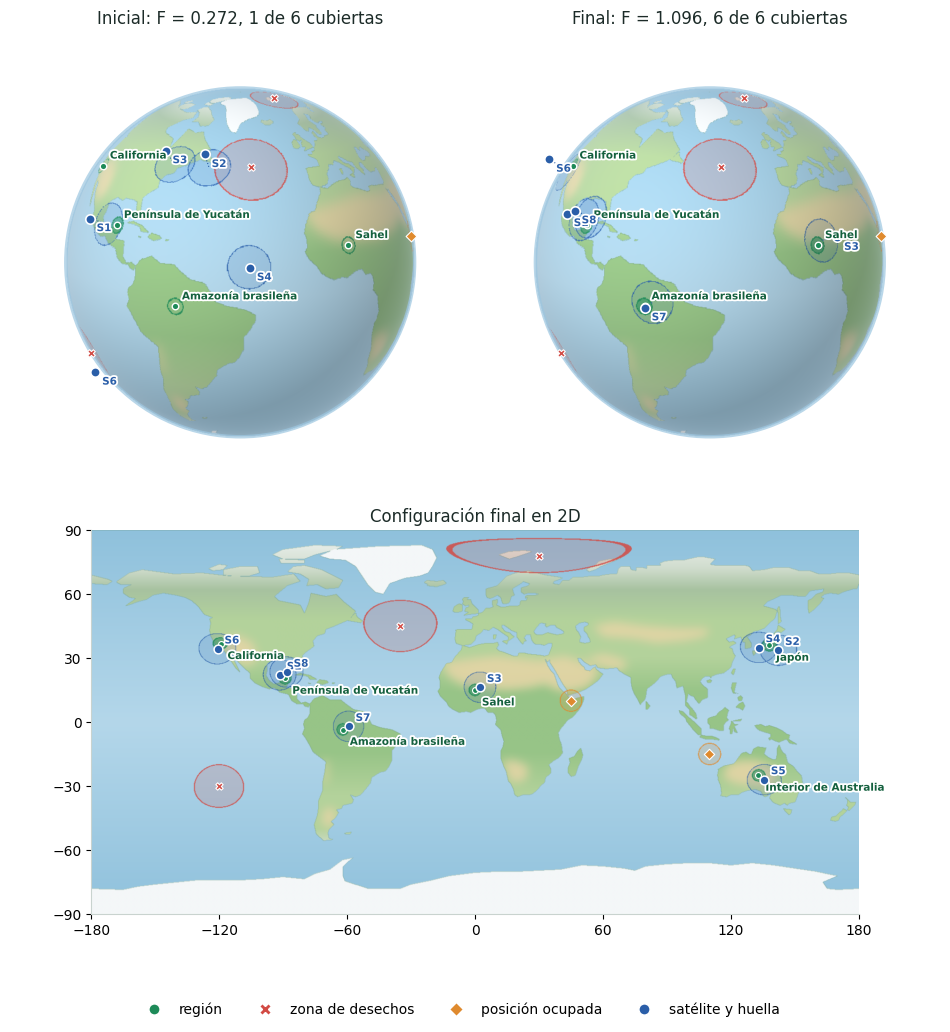

In [73]:
import html as html_lib
from IPython.display import HTML, Markdown, display
from matplotlib.lines import Line2D
from matplotlib.path import Path as RutaMpl
import matplotlib.patheffects as _pe
from scipy.ndimage import gaussian_filter


def md(texto):
    display(Markdown(texto))


# ---------- datos para el globo ----------
def observadores_por_region(config, esc):
    pts, idx = muestras_regiones(esc)
    c = np.asarray(config, dtype=float)
    rho = radio_huella_deg(esc.altura_km, esc.elevacion_min_deg)
    dentro = distancia_angular(pts[:, None, 0], pts[:, None, 1], c[None, :, 0], c[None, :, 1]) <= rho
    return [np.nonzero(dentro[idx == i].any(axis=0))[0].tolist() for i in range(len(esc.regiones))]


def problemas_de(config, esc):
    c = np.asarray(config, dtype=float)
    salida = []
    for z in esc.zonas:
        d = distancia_angular(z.lat, z.lon, c[:, 0], c[:, 1])
        for j in np.nonzero(d < z.radio_deg)[0]:
            salida.append(f"S{j + 1} invade {z.nombre}: {z.radio_deg - d[j]:.2f} grados dentro")
    ds = distancia_angular(c[:, None, 0], c[:, None, 1], c[None, :, 0], c[None, :, 1])
    for a, b in zip(*np.triu_indices(len(c), k=1)):
        if ds[a, b] < esc.separacion_min_deg:
            salida.append(f"S{a + 1} y S{b + 1} demasiado cerca ({ds[a, b]:.2f} grados)")
    return salida


def estado_vista(config, esc, gen, etiqueta):
    config = np.asarray(config, dtype=float)
    ev = evaluar_con_restricciones(config, esc)
    cob = cobertura_por_region(config, esc)
    obs = observadores_por_region(config, esc)
    return {
        "gen": int(gen), "etiqueta": etiqueta,
        "sats": [{"id": f"S{j + 1}", "lat": round(float(a), 4), "lon": round(float(b), 4)} for j, (a, b) in enumerate(config)],
        "eval": {"F": ev["fitness"], "cobertura": ev["cobertura"], "redundancia": ev["redundancia"],
                 "cubiertas": ev["cubiertas"], "violacion": ev["violacion"], "valida": ev["violacion"] == 0},
        "regiones": {f"r{i}": {"f": float(fila.f), "d": float(fila.d), "cubierta": bool(fila.cubierta), "obs": obs[i]}
                     for i, fila in enumerate(cob.itertuples())},
        "problemas": problemas_de(config, esc),
    }


def vista(titulo, descripcion, res, esc, inicial=None, etiqueta_inicial=None, nota=""):
    h = res["historial"]
    f_ref = calidad_maxima_alcanzable(esc)
    if f_ref <= 0:
        f_ref = calidad_maxima_teorica(esc)
    cfg_ini = res["inicial"]["config"] if inicial is None else inicial
    return {
        "titulo": titulo, "descripcion": descripcion, "nota": nota,
        "rho": radio_huella_deg(esc.altura_km, esc.elevacion_min_deg), "umbral": esc.umbral_cubierta,
        "elev": 3 * esc.altura_km / R_TIERRA_KM,
        "f_ref": f_ref, "semilla": res["params"].semilla, "evaluaciones": res["evaluaciones"], "parada": res["parada"],
        "regiones": [{"id": f"r{i}", "nombre": r.nombre, "lat": r.lat, "lon": r.lon, "prioridad": r.prioridad,
                      "radio": float(km_a_grados(r.radio_km))} for i, r in enumerate(esc.regiones)],
        "zonas": [{"nombre": z.nombre, "lat": z.lat, "lon": z.lon, "radio": z.radio_deg, "tipo": z.tipo} for z in esc.zonas],
        "estados": {
            "inicial": estado_vista(cfg_ini, esc, 0, etiqueta_inicial or "Configuración inicial (generación 0)"),
            "final": estado_vista(res["mejor"]["config"], esc, res["generacion_mejor"],
                                  f"Configuración final (generación {res['generacion_mejor']})"),
        },
        "historial": {"gen": h["generacion"].astype(int).tolist(), "mejor": h["mejor_global"].round(5).tolist(),
                      "media": h["media"].round(5).tolist()},
    }


def pagina_globo(vistas):
    datos = json.dumps(vistas, ensure_ascii=False, separators=(",", ":"))
    cuerpo = PLANTILLA_GLOBO.replace("/*__MUNDO__*/null", json.dumps(MUNDO, separators=(",", ":")))
    cuerpo = cuerpo.replace("/*__DATOS__*/null", datos)
    return ('<!doctype html>\n<html lang="es">\n<head>\n<meta charset="utf-8">\n'
            '<meta name="viewport" content="width=device-width, initial-scale=1">\n</head>\n<body>\n'
            + cuerpo + "\n</body>\n</html>\n")


def mostrar_globo(pagina, alto=1750):
    display(HTML(f'<iframe srcdoc="{html_lib.escape(pagina, quote=True)}" '
                 f'style="width:100%;height:{alto}px;border:0;border-radius:12px"></iframe>'))


# ---------- globo interactivo ----------
VISTAS_GLOBO = [
    vista("Escenario base", "Escenario oficial (§8, semilla 42).", res_etapa2, esc_base),
    vista("Sin restricciones", "Misma búsqueda sin zonas (§6).", res_etapa1, esc_etapa1),
    vista("Zona nueva", "§9: zona nueva sobre un satélite. Inicial = solución anterior.",
          res_cambio_b, esc_zona_nueva, inicial=config_e2,
          etiqueta_inicial="Solución anterior (§8) en el escenario nuevo"),
    vista("Espacio reducido", "§10: radios x1.5 y zona extra en la Amazonía.",
          res_reducido, esc_reducido),
    vista("Yucatán bloqueada", "§10 (a): Yucatán no se puede observar.",
          res_bloqueo, esc_bloqueo),
    vista("Sin solución válida", "§10 (b): todo el globo prohibido.",
          res_imposible, esc_imposible),
]

PAGINA_GLOBO = pagina_globo(VISTAS_GLOBO)
with open("globo_astroshield.html", "w", encoding="utf-8") as fh:
    fh.write(PAGINA_GLOBO)
print("Exportado a globo_astroshield.html")
mostrar_globo(PAGINA_GLOBO)


# ---------- comprobación: el globo coincide con los resultados ----------
def datos_de_pagina(pagina):
    inicio = pagina.index("window.ASTRO = ") + len("window.ASTRO = ")
    return json.loads(pagina[inicio:pagina.index(";\n</script>", inicio)])


fuentes = [
    (res_etapa2["inicial"]["config"], res_etapa2["mejor"]["config"], esc_base),
    (res_etapa1["inicial"]["config"], res_etapa1["mejor"]["config"], esc_etapa1),
    (config_e2, res_cambio_b["mejor"]["config"], esc_zona_nueva),
    (res_reducido["inicial"]["config"], res_reducido["mejor"]["config"], esc_reducido),
    (res_bloqueo["inicial"]["config"], res_bloqueo["mejor"]["config"], esc_bloqueo),
    (res_imposible["inicial"]["config"], res_imposible["mejor"]["config"], esc_imposible),
]
en_pagina = datos_de_pagina(PAGINA_GLOBO)
filas_chk = []
for v, (cfg_i, cfg_f, esc) in zip(en_pagina, fuentes):
    for nombre, cfg in (("inicial", cfg_i), ("final", cfg_f)):
        st = v["estados"][nombre]
        dib = np.array([[s["lat"], s["lon"]] for s in st["sats"]])
        assert np.allclose(dib, cfg, atol=1e-4)
        cub_dib = [st["regiones"][f"r{i}"]["cubierta"] for i in range(len(esc.regiones))]
        assert cub_dib == cobertura_por_region(cfg, esc)["cubierta"].tolist()
        filas_chk.append({"escenario": v["titulo"], "estado": nombre, "cubiertas": sum(cub_dib), "válida": st["eval"]["valida"]})
print("El globo coincide con los resultados en los 6 escenarios.")
display(pd.DataFrame(filas_chk))


# ---------- vista estática (para GitHub o PDF) ----------
PALETA = {"oceano": "#b4d7ea", "oceano_prof": "#8fc1dc", "hielo": "#f4f7f8", "desierto": "#e5d5a6", "costa": "#6f9a83",
          "sat": "#2a5ea8", "region": "#1d8a58", "desechos": "#d24b45", "ocupada": "#df8a2e",
          "tinta": "#1c2b28", "gris": "#5b6b66"}
_VEGETACION = [(-90, "#f4f7f8"), (-64, "#f4f7f8"), (-58, "#d0dccd"), (-50, "#b3d29b"), (-34, "#b3d29b"), (-14, "#97c487"),
               (14, "#97c487"), (30, "#b3d29b"), (48, "#b3d29b"), (62, "#a7c2a0"), (72, "#d0dccd"), (90, "#f4f7f8")]
ESTILO = {"figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#c9d3cf", "axes.grid": True,
          "grid.color": "#e6ece9", "axes.spines.top": False, "axes.spines.right": False, "font.size": 10}
_halo = [_pe.withStroke(linewidth=2.6, foreground="white")]


def _rgb(h):
    return np.array([int(h[i:i + 2], 16) for i in (1, 3, 5)]) / 255.0


def textura_mundo(config, esc, ancho=1440):
    alto = ancho // 2
    lon = np.linspace(-180, 180, ancho, endpoint=False) + 180 / ancho
    lat = np.linspace(90, -90, alto, endpoint=False) - 90 / alto
    LON, LAT = np.meshgrid(lon, lat)
    pts = np.column_stack([LON.ravel(), LAT.ravel()])

    def mascara(poligonos):
        m = np.zeros(len(pts), bool)
        for p in poligonos:
            p = np.asarray(p, float)
            (x0, y0), (x1, y1) = p.min(0), p.max(0)
            sel = (pts[:, 0] >= x0) & (pts[:, 0] <= x1) & (pts[:, 1] >= y0) & (pts[:, 1] <= y1)
            m[sel] |= RutaMpl(p).contains_points(pts[sel])
        return m.reshape(alto, ancho)

    tierra = mascara([t["p"] for t in MUNDO["tierra"]]) & ~mascara(MUNDO["agua"])
    hielo = mascara([t["p"] for t in MUNDO["tierra"] if t["hielo"]])
    desierto = gaussian_filter(mascara(MUNDO["desiertos"]).astype(float), sigma=ancho / 360 * 2.2) * 0.9
    la_s, cols = zip(*_VEGETACION)
    veg = np.stack([np.interp(LAT, la_s, [_rgb(c)[k] for c in cols]) for k in range(3)], -1)
    t_oc = (np.abs(LAT) / 90)[..., None]
    img = _rgb(PALETA["oceano"]) * (1 - t_oc) + _rgb(PALETA["oceano_prof"]) * t_oc
    veg = veg * (1 - desierto[..., None]) + _rgb(PALETA["desierto"]) * desierto[..., None]
    veg[hielo] = _rgb(PALETA["hielo"])
    img[tierra] = veg[tierra]
    borde = tierra ^ np.roll(tierra, 1, 0) | tierra ^ np.roll(tierra, 1, 1)
    img[borde] = img[borde] * 0.55 + _rgb(PALETA["costa"]) * 0.45

    def capa(lat0, lon0, radio, color, a_relleno, ancho_borde=0.45):
        d = distancia_angular(LAT, LON, lat0, lon0)
        c = _rgb(color)
        m = (d <= radio)[..., None]
        img[:] = np.where(m, img * (1 - a_relleno) + c * a_relleno, img)
        b = np.abs(d - radio) <= ancho_borde * 0.5
        img[b] = img[b] * 0.15 + c * 0.85

    rho = radio_huella_deg(esc.altura_km, esc.elevacion_min_deg)
    for z in esc.zonas:
        capa(z.lat, z.lon, z.radio_deg, PALETA["desechos"] if z.tipo == "desechos" else PALETA["ocupada"], 0.17)
    for a, b in np.asarray(config):
        capa(a, b, rho, PALETA["sat"], 0.13, 0.3)
    cub = cobertura_por_region(config, esc)["cubierta"].tolist()
    for r, ok in zip(esc.regiones, cub):
        capa(r.lat, r.lon, km_a_grados(r.radio_km), PALETA["region"], 0.5 if ok else 0.08)
    return np.clip(img, 0, 1)


def _proyectar(lat, lon, lon0, lat0, radio=1.0):
    p, l = np.radians(lat), np.radians(np.asarray(lon) - lon0)
    cp, sp = np.cos(np.radians(lat0)), np.sin(np.radians(lat0))
    x, y, z = np.cos(p) * np.sin(l), np.sin(p), np.cos(p) * np.cos(l)
    return x * radio, (y * cp - z * sp) * radio, (y * sp + z * cp) * radio


def globo_estatico(ax, textura, config, esc, lon0, lat0, titulo, n=560):
    v = np.linspace(-1, 1, n)
    X, Y = np.meshgrid(v, -v)
    rr = X ** 2 + Y ** 2
    dentro = rr <= 1
    Z = np.sqrt(np.clip(1 - rr, 0, 1))
    cp, sp = np.cos(np.radians(lat0)), np.sin(np.radians(lat0))
    lat = np.degrees(np.arcsin(np.clip(Y * cp + Z * sp, -1, 1)))
    lon = (lon0 + np.degrees(np.arctan2(X, -Y * sp + Z * cp)) + 180) % 360 - 180
    alto, ancho = textura.shape[:2]
    u = np.clip(((lon + 180) / 360 * ancho).astype(int), 0, ancho - 1)
    w = np.clip(((90 - lat) / 180 * alto).astype(int), 0, alto - 1)
    col = textura[w, u]
    luz = np.array([-0.4, 0.45, 0.8]) / np.linalg.norm([-0.4, 0.45, 0.8])
    sombra = 0.72 + 0.36 * np.clip(X * luz[0] + Y * luz[1] + Z * luz[2], 0, None)
    bruma = ((1 - Z) ** 2.2 * 0.45)[..., None]
    col = np.clip(col * sombra[..., None] * (1 - bruma) + np.array([214, 232, 248]) / 255 * bruma, 0, 1)
    ax.imshow(np.dstack([col, dentro.astype(float)]), extent=(-1, 1, -1, 1), interpolation="bilinear", zorder=1)
    ax.add_patch(plt.Circle((0, 0), 1.0, fill=False, ec="#9cc6e0", lw=2.5, alpha=0.7, zorder=2))
    elev = 1 + 1.5 * esc.altura_km / R_TIERRA_KM
    for r in esc.regiones:
        x, y, z = _proyectar(r.lat, r.lon, lon0, lat0)
        if z > 0:
            ax.scatter(x, y, s=22, c=PALETA["region"], ec="white", lw=1, zorder=4)
            ax.annotate(r.nombre, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=7.5,
                        color="#14603e", weight="bold", zorder=6, path_effects=_halo)
    for z_ in esc.zonas:
        x, y, z = _proyectar(z_.lat, z_.lon, lon0, lat0)
        if z > 0:
            ax.scatter(x, y, s=30, c=PALETA["desechos"] if z_.tipo == "desechos" else PALETA["ocupada"],
                       marker="X" if z_.tipo == "desechos" else "D", ec="white", lw=0.8, zorder=4)
    for j, (a, b) in enumerate(np.asarray(config)):
        x0, y0, z0 = _proyectar(a, b, lon0, lat0)
        x, y, z = _proyectar(a, b, lon0, lat0, elev)
        if z > 0 or np.hypot(x, y) > 1:
            if z0 > 0:
                ax.plot([x0, x], [y0, y], color=PALETA["sat"], lw=0.8, ls=":", zorder=4)
            ax.scatter(x, y, s=46, c=PALETA["sat"], ec="white", lw=1.2, zorder=5)
            ax.annotate(f"S{j + 1}", (x, y), xytext=(5, -9), textcoords="offset points", fontsize=7.5,
                        color=PALETA["sat"], weight="bold", zorder=6, path_effects=_halo)
    ax.set_xlim(-1.32, 1.32)
    ax.set_ylim(-1.32, 1.32)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(titulo, color=PALETA["tinta"])


def mapa_estatico(ax, textura, config, esc, titulo):
    ax.imshow(textura, extent=(-180, 180, -90, 90), interpolation="bilinear")
    for r in esc.regiones:
        ax.scatter(r.lon, r.lat, s=18, c=PALETA["region"], ec="white", lw=0.8, zorder=4)
        ax.annotate(r.nombre, (r.lon, r.lat), xytext=(5, -11), textcoords="offset points", fontsize=7.5,
                    color="#14603e", weight="bold", path_effects=_halo)
    for z in esc.zonas:
        ax.scatter(z.lon, z.lat, s=28, c=PALETA["desechos"] if z.tipo == "desechos" else PALETA["ocupada"],
                   marker="X" if z.tipo == "desechos" else "D", ec="white", lw=0.8, zorder=4)
    c = np.asarray(config)
    ax.scatter(c[:, 1], c[:, 0], s=40, c=PALETA["sat"], ec="white", lw=1.1, zorder=5)
    for j, (a, b) in enumerate(c):
        ax.annotate(f"S{j + 1}", (b, a), xytext=(5, 4), textcoords="offset points", fontsize=7.5,
                    color=PALETA["sat"], weight="bold", path_effects=_halo)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks(range(-180, 181, 60))
    ax.set_yticks(range(-90, 91, 30))
    ax.grid(False)
    ax.set_title(titulo, color=PALETA["tinta"])


ini, fin = res_etapa2["inicial"], res_etapa2["mejor"]
tex_ini, tex_fin = textura_mundo(ini["config"], esc_base), textura_mundo(fin["config"], esc_base)
with plt.rc_context(ESTILO):
    fig = plt.figure(figsize=(12, 11.5))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.82], hspace=0.08, wspace=0.02)
    globo_estatico(fig.add_subplot(gs[0, 0]), tex_ini, ini["config"], esc_base, -40, 12,
                   f"Inicial: F = {ini['eval']['fitness']:.3f}, {ini['eval']['cubiertas']} de 6 cubiertas")
    globo_estatico(fig.add_subplot(gs[0, 1]), tex_fin, fin["config"], esc_base, -40, 12,
                   f"Final: F = {fin['eval']['fitness']:.3f}, {fin['eval']['cubiertas']} de 6 cubiertas")
    mapa_estatico(fig.add_subplot(gs[1, :]), tex_fin, fin["config"], esc_base, "Configuración final en 2D")
    leyenda = [Line2D([], [], marker="o", ls="", mfc=PALETA["region"], mec="white", ms=8, label="región"),
               Line2D([], [], marker="X", ls="", mfc=PALETA["desechos"], mec="white", ms=8, label="zona de desechos"),
               Line2D([], [], marker="D", ls="", mfc=PALETA["ocupada"], mec="white", ms=7, label="posición ocupada"),
               Line2D([], [], marker="o", ls="", mfc=PALETA["sat"], mec="white", ms=8, label="satélite y huella")]
    fig.legend(handles=leyenda, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.01))
    fig.savefig("globo_astroshield.png", dpi=130, bbox_inches="tight")
    plt.show()

## §12. Variación entre ejecuciones

10 semillas (0 a 9), mismas condiciones. Se compara la calidad final, qué tan distintas quedan las constelaciones y el efecto de las restricciones.

,calidad F,regiones cubiertas,Alta con d ≥ 0.9,violación,evaluaciones,generación del mejor
semilla,,,,,,
0,1.1154,6,2,0.0,11468,66
1,1.1154,6,2,0.0,14042,99
2,1.0962,6,1,0.0,12014,73
3,1.0962,6,1,0.0,10220,50
4,1.1154,6,2,0.0,8426,27
5,1.0962,6,1,0.0,14042,99
6,1.0962,6,1,0.0,10532,54
7,1.1154,6,2,0.0,11702,69
8,1.1154,6,2,0.0,12950,85


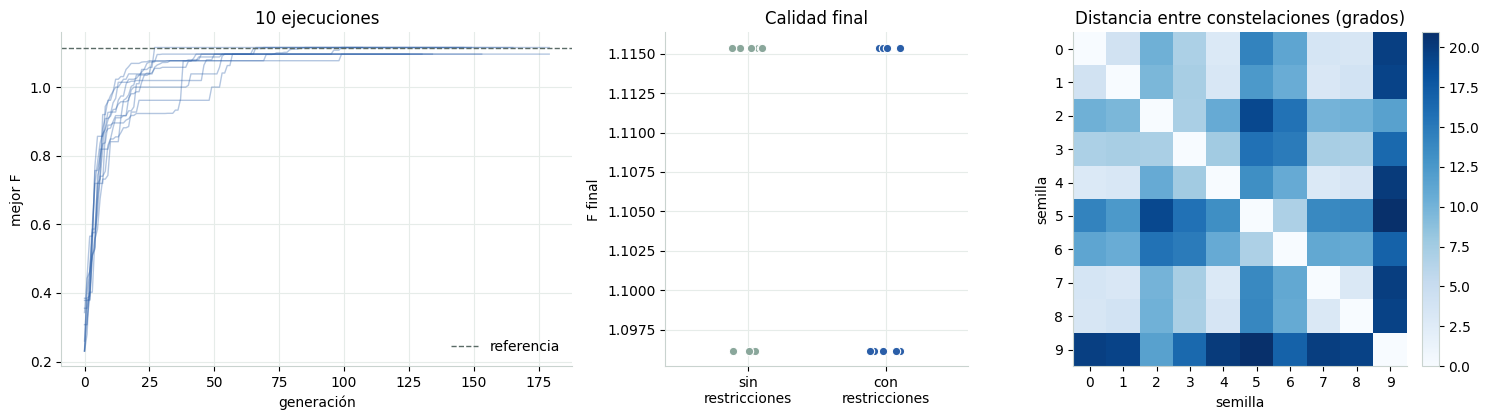

**Resultado.** F = 1.106 ± 0.010; 10 de 10 cubren las 6 regiones.
Las constelaciones quedan a 10.8 grados en promedio entre sí: hay varias soluciones casi igual de buenas.
Sin restricciones la mediana es 1.115; con restricciones, 1.106.

In [69]:
from scipy.optimize import linear_sum_assignment

SEMILLAS = list(range(10))
res_semillas = [evolucionar_con_restricciones(esc_base, ParametrosGA(semilla=s)) for s in SEMILLAS]
res_sin_restr = [evolucionar(esc_etapa1, ParametrosGA(semilla=s)) for s in SEMILLAS]


def fila_ejecucion(res, s, esc):
    ev, cfg = res["mejor"]["eval"], res["mejor"]["config"]
    cob = cobertura_por_region(cfg, esc)
    return {"semilla": s, "calidad F": ev["fitness"], "regiones cubiertas": ev["cubiertas"],
            "Alta con d ≥ 0.9": int((cob.loc[cob["prioridad"] == "Alta", "d"] >= 0.9).sum()),
            "violación": ev["violacion"], "evaluaciones": res["evaluaciones"], "generación del mejor": res["generacion_mejor"]}


def distancia_configuraciones(a, b):
    d = distancia_angular(a[:, None, 0], a[:, None, 1], b[None, :, 0], b[None, :, 1])
    r, c = linear_sum_assignment(d)
    return float(d[r, c].mean())


tabla_semillas = pd.DataFrame([fila_ejecucion(r, s, esc_base) for r, s in zip(res_semillas, SEMILLAS)]).set_index("semilla")
assert (tabla_semillas["violación"] == 0).all()
display(tabla_semillas.round(4))

configs_finales = [r["mejor"]["config"] for r in res_semillas]
m = np.array([[distancia_configuraciones(a, b) for b in configs_finales] for a in configs_finales])
pares = m[np.triu_indices(len(m), k=1)]
f_con = tabla_semillas["calidad F"].values
f_sin = np.array([r["mejor"]["eval"]["fitness"] for r in res_sin_restr])

with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.35, 0.8, 1]})
    for r in res_semillas:
        ax[0].plot(r["historial"]["generacion"], r["historial"]["mejor_global"], color=PALETA["sat"], alpha=0.35, lw=1)
    ax[0].axhline(F_MAX, ls="--", c=PALETA["gris"], lw=1, label="referencia")
    ax[0].set(xlabel="generación", ylabel="mejor F", title="10 ejecuciones")
    ax[0].legend(loc="lower right", frameon=False)
    for k, (vals, col) in enumerate([(f_sin, "#8aa79b"), (f_con, PALETA["sat"])]):
        x = k + np.random.default_rng(k).uniform(-0.12, 0.12, len(vals))
        ax[1].scatter(x, vals, s=36, c=col, ec="white", lw=0.8, zorder=3)
    ax[1].set_xticks([0, 1], ["sin\nrestricciones", "con\nrestricciones"])
    ax[1].set(ylabel="F final", title="Calidad final", xlim=(-0.6, 1.6))
    im = ax[2].imshow(m, cmap="Blues", vmin=0)
    ax[2].set_xticks(range(10), SEMILLAS)
    ax[2].set_yticks(range(10), SEMILLAS)
    ax[2].grid(False)
    ax[2].set(xlabel="semilla", ylabel="semilla", title="Distancia entre constelaciones (grados)")
    fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

md(f"""**Resultado.** F = {f_con.mean():.3f} ± {f_con.std(ddof=1):.3f}; {int((tabla_semillas['regiones cubiertas'] == 6).sum())} de 10 cubren las 6 regiones.
Las constelaciones quedan a {pares.mean():.1f} grados en promedio entre sí: hay varias soluciones casi igual de buenas.
Sin restricciones la mediana es {np.median(f_sin):.3f}; con restricciones, {np.median(f_con):.3f}.""")

## §13. Prueba propia: algoritmo evolutivo vs. búsqueda aleatoria

Misma cantidad de evaluaciones, misma evaluación y misma reparación. Solo cambia que la búsqueda aleatoria no evoluciona.

,evaluaciones,F evolutivo,F aleatoria,cubiertas evolutivo,cubiertas aleatoria,diferencia
semilla,,,,,,
0,11468,1.1154,0.4615,6,2,0.6538
1,14042,1.1154,0.4969,6,2,0.6185
2,12014,1.0962,0.5156,6,3,0.5806
3,10220,1.0962,0.5192,6,2,0.5769
4,8426,1.1154,0.4740,6,2,0.6414
5,14042,1.0962,0.4886,6,2,0.6076
6,10532,1.0962,0.6154,6,3,0.4808
7,11702,1.1154,0.5198,6,1,0.5956
8,12950,1.1154,0.5426,6,1,0.5728


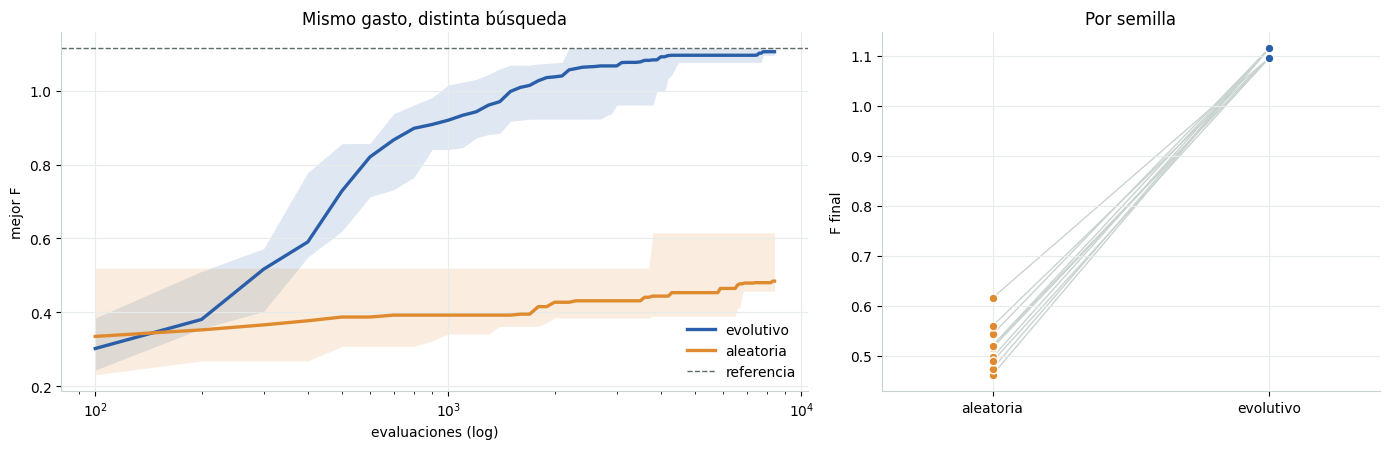

**Resultado.** El evolutivo gana en 10 de 10 semillas: F 1.106 contra 0.519
(Mann-Whitney p = 7.3e-05). La calidad viene de la evolución, no de probar muchas configuraciones.

In [72]:
from scipy.stats import mannwhitneyu


def busqueda_aleatoria(esc, presupuesto, semilla, cada=100):
    rng = np.random.default_rng(semilla)
    mejor, curva = None, []
    for k in range(1, presupuesto + 1):
        ind = reparar(rng, posiciones_aleatorias(rng, esc.n_satelites), esc)
        ev = evaluar_con_restricciones(ind, esc)
        if mejor is None or clave_deb(ev) > clave_deb(mejor["eval"]):
            mejor = {"config": ind, "eval": ev}
        if k % cada == 0 or k == presupuesto:
            curva.append((k, mejor["eval"]["fitness"] if mejor["eval"]["violacion"] == 0 else np.nan))
    mejor["curva"] = pd.DataFrame(curva, columns=["evaluaciones", "mejor"])
    return mejor


def curva_evolutivo(res):
    p, h = res["params"], res["historial"]
    return pd.DataFrame({"evaluaciones": p.poblacion + (p.poblacion - p.elitismo) * h["generacion"], "mejor": h["mejor_global"]})


res_azar = [busqueda_aleatoria(esc_base, r["evaluaciones"], s) for r, s in zip(res_semillas, SEMILLAS)]
tabla_azar = pd.DataFrame({
    "evaluaciones": [r["evaluaciones"] for r in res_semillas],
    "F evolutivo": [r["mejor"]["eval"]["fitness"] for r in res_semillas],
    "F aleatoria": [a["eval"]["fitness"] for a in res_azar],
    "cubiertas evolutivo": [r["mejor"]["eval"]["cubiertas"] for r in res_semillas],
    "cubiertas aleatoria": [a["eval"]["cubiertas"] for a in res_azar],
}, index=SEMILLAS).rename_axis("semilla")
tabla_azar["diferencia"] = tabla_azar["F evolutivo"] - tabla_azar["F aleatoria"]
display(tabla_azar.round(4))
gana_ga = int((tabla_azar["diferencia"] > 0).sum())
prueba_u = mannwhitneyu(tabla_azar["F evolutivo"], tabla_azar["F aleatoria"], alternative="greater")

rejilla = np.arange(100, int(tabla_azar["evaluaciones"].min()) + 1, 100)
ga_r = np.array([np.interp(rejilla, c["evaluaciones"], c["mejor"]) for c in map(curva_evolutivo, res_semillas)])
az_r = np.array([np.interp(rejilla, a["curva"]["evaluaciones"], a["curva"]["mejor"]) for a in res_azar])
with plt.rc_context(ESTILO):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
    for datos, col, nombre in [(ga_r, PALETA["sat"], "evolutivo"), (az_r, PALETA["ocupada"], "aleatoria")]:
        ax[0].fill_between(rejilla, np.nanmin(datos, 0), np.nanmax(datos, 0), color=col, alpha=0.15, lw=0)
        ax[0].plot(rejilla, np.nanmedian(datos, 0), color=col, lw=2.4, label=nombre)
    ax[0].axhline(F_MAX, ls="--", c=PALETA["gris"], lw=1, label="referencia")
    ax[0].set_xscale("log")
    ax[0].set(xlabel="evaluaciones (log)", ylabel="mejor F", title="Mismo gasto, distinta búsqueda")
    ax[0].legend(frameon=False)
    for s in SEMILLAS:
        ax[1].plot([0, 1], tabla_azar.loc[s, ["F aleatoria", "F evolutivo"]], color="#c9d3cf", lw=1, zorder=1)
    ax[1].scatter(np.zeros(10), tabla_azar["F aleatoria"], s=40, c=PALETA["ocupada"], ec="white", zorder=3)
    ax[1].scatter(np.ones(10), tabla_azar["F evolutivo"], s=40, c=PALETA["sat"], ec="white", zorder=3)
    ax[1].set_xticks([0, 1], ["aleatoria", "evolutivo"])
    ax[1].set(xlim=(-0.4, 1.4), ylabel="F final", title="Por semilla")
    plt.tight_layout()
    plt.show()

md(f"""**Resultado.** El evolutivo gana en {gana_ga} de {len(SEMILLAS)} semillas: F {tabla_azar['F evolutivo'].mean():.3f} contra {tabla_azar['F aleatoria'].mean():.3f}
(Mann-Whitney p = {prueba_u.pvalue:.2g}). La calidad viene de la evolución, no de probar muchas configuraciones.""")

## §14. Análisis de resultados (Entregable 4)

Todas las cifras salen de las ejecuciones de arriba; no están escritas a mano.

In [39]:
mejor_idx = int(tabla_semillas["calidad F"].idxmax())
res_mejor = res_semillas[mejor_idx]
cob_mejor = cobertura_por_region(res_mejor["mejor"]["config"], esc_base)

md(f"""### ¿Qué tan bien se observan las regiones en la configuración final?

En la mejor de las 10 ejecuciones (semilla {mejor_idx}, F = {res_mejor['mejor']['eval']['fitness']:.4f}, {100 * res_mejor['mejor']['eval']['fitness'] / F_MAX:.1f} % de la referencia) se cubren
**{int(cob_mejor['cubierta'].sum())} de {len(cob_mejor)} regiones** y la violación es {res_mejor['mejor']['eval']['violacion']:.0f}.
Entre las 10 ejecuciones, el número de regiones cubiertas va de {int(tabla_semillas['regiones cubiertas'].min())} a {int(tabla_semillas['regiones cubiertas'].max())}
y {int((tabla_semillas['regiones cubiertas'] == 6).sum())} de 10 las cubren todas.
""")
cob_mejor[["region", "prioridad", "f", "d", "cubierta", "dist_sat_mas_cercano"]].round(3)

### ¿Qué tan bien se observan las regiones en la configuración final?

En la mejor de las 10 ejecuciones (semilla 0, F = 1.1154, 100.0 % de la referencia) se cubren
**6 de 6 regiones** y la violación es 0.
Entre las 10 ejecuciones, el número de regiones cubiertas va de 6 a 6
y 10 de 10 las cubren todas.


,region,prioridad,f,d,cubierta,dist_sat_mas_cercano
0,Península de Yucatán,Alta,1.0,1.0,True,1.399
1,Amazonía brasileña,Alta,1.0,1.0,True,2.284
2,California,Media,1.0,0.0,True,2.847
3,Sahel,Media,1.0,0.0,True,3.912
4,Japón,Media,1.0,0.0,True,2.031
5,Interior de Australia,Normal,1.0,0.0,True,2.066


## §14. Análisis de resultados 2

In [40]:
def gen_que_alcanza(res, frac):
    h = res["historial"]
    final = h["mejor_global"].iloc[-1]
    return int(h.loc[h["mejor_global"] >= frac * final, "generacion"].iloc[0])


g95 = [gen_que_alcanza(r, 0.95) for r in res_semillas]
g99 = [gen_que_alcanza(r, 0.99) for r in res_semillas]
ini_f = [r["inicial"]["eval"]["fitness"] for r in res_semillas]
fin_f = tabla_semillas["calidad F"].values

md(f"""### ¿Cómo cambió la calidad durante el proceso evolutivo?

La mejor calidad de la generación 0 fue {np.mean(ini_f):.3f} en promedio (rango {min(ini_f):.3f} a {max(ini_f):.3f}); la final, {fin_f.mean():.3f} (rango {fin_f.min():.3f} a {fin_f.max():.3f}).
En promedio se alcanza el 95 % de la calidad final en la generación {np.mean(g95):.0f} y el 99 % en la {np.mean(g99):.0f}; el resto de las generaciones solo afina.
La media de la población queda por debajo de la mejor ({np.mean([r['historial']['media'].iloc[-1] for r in res_semillas]):.3f} frente a {fin_f.mean():.3f} en la última generación) porque la mutación sigue produciendo individuos peores.
""")

### ¿Cómo cambió la calidad durante el proceso evolutivo?

La mejor calidad de la generación 0 fue 0.295 en promedio (rango 0.231 a 0.385); la final, 1.106 (rango 1.096 a 1.115).
En promedio se alcanza el 95 % de la calidad final en la generación 35 y el 99 % en la 65; el resto de las generaciones solo afina.
La media de la población queda por debajo de la mejor (0.973 frente a 1.106 en la última generación) porque la mutación sigue produciendo individuos peores.


## §14. Análisis de resultados 3

In [41]:
dif_restr = tabla_semillas["calidad F"].values - np.array([r["mejor"]["eval"]["fitness"] for r in res_sin_restr])
invalidas = sum(evaluar_con_restricciones(r["mejor"]["config"], esc_base)["violacion"] > 0 for r in res_sin_restr)

md(f"""### ¿Qué diferencias hay entre ejecuciones?

Con las mismas condiciones y solo cambiando la semilla, la calidad final varía entre {fin_f.min():.4f} y {fin_f.max():.4f} (media {fin_f.mean():.4f}, desviación {fin_f.std(ddof=1):.4f}).
Las configuraciones finales de dos ejecuciones distintas están a {pares.mean():.1f} grados de distancia media: el algoritmo **no encuentra siempre la misma constelación**, hay varias configuraciones de calidad parecida.
Que el algoritmo deje de mejorar no demuestra que haya encontrado la mejor posible: {int((tabla_semillas['calidad F'] < F_MAX - 1e-6).sum())} de 10 ejecuciones terminaron por debajo de la referencia teórica de {F_MAX:.4f}.

### ¿Qué efecto tuvieron las restricciones espaciales?

En el escenario base, las zonas están lejos de las seis regiones, así que casi no cuestan calidad: la diferencia media entre la serie con restricciones y sin ellas es {dif_restr.mean():+.4f}.
El efecto real es de validez: de las 10 soluciones obtenidas **sin** restricciones, {invalidas} {'habría violado' if invalidas == 1 else 'habrían violado'} alguna zona al aplicarlas.
Cuando la restricción sí interfiere el efecto es grande (§10): con el espacio reducido la calidad fue {res_reducido['mejor']['eval']['fitness']:.4f} y con Yucatán bloqueada, {res_bloqueo['mejor']['eval']['fitness']:.4f}.
""")

### ¿Qué diferencias hay entre ejecuciones?

Con las mismas condiciones y solo cambiando la semilla, la calidad final varía entre 1.0962 y 1.1154 (media 1.1058, desviación 0.0101).
Las configuraciones finales de dos ejecuciones distintas están a 10.8 grados de distancia media: el algoritmo **no encuentra siempre la misma constelación**, hay varias configuraciones de calidad parecida.
Que el algoritmo deje de mejorar no demuestra que haya encontrado la mejor posible: 5 de 10 ejecuciones terminaron por debajo de la referencia teórica de 1.1154.

### ¿Qué efecto tuvieron las restricciones espaciales?

En el escenario base, las zonas están lejos de las seis regiones, así que casi no cuestan calidad: la diferencia media entre la serie con restricciones y sin ellas es -0.0019.
El efecto real es de validez: de las 10 soluciones obtenidas **sin** restricciones, 1 habría violado alguna zona al aplicarlas.
Cuando la restricción sí interfiere el efecto es grande (§10): con el espacio reducido la calidad fue 1.0962 y con Yucatán bloqueada, 0.9038.


## §14. Análisis de resultados 4



In [42]:
md(f"""### ¿Qué sucede cuando el sistema no puede satisfacer todas las condiciones?

- **Región imposible de cubrir** (§10a): el sistema la detecta antes de evolucionar ({regiones_inalcanzables(esc_bloqueo)}), reparte los satélites entre las demás
  y devuelve una configuración **válida** con {res_bloqueo['mejor']['eval']['cubiertas']} de 6 regiones cubiertas y calidad {res_bloqueo['mejor']['eval']['fitness']:.4f},
  igual al máximo alcanzable ({calidad_maxima_alcanzable(esc_bloqueo):.4f}).
- **Sin ninguna configuración válida** (§10b): ninguna de las {res_imposible['evaluaciones']} configuraciones evaluadas cumplió las restricciones y el sistema lo informa
  ({res_imposible['historial']['validos'].max()} individuos válidos en todas las generaciones) en lugar de devolver la menos mala como solución.
""")

### ¿Qué sucede cuando el sistema no puede satisfacer todas las condiciones?

- **Región imposible de cubrir** (§10a): el sistema la detecta antes de evolucionar ([('Península de Yucatán', 'Bloqueo Yucatán')]), reparte los satélites entre las demás
  y devuelve una configuración **válida** con 5 de 6 regiones cubiertas y calidad 0.9038,
  igual al máximo alcanzable (0.9038).
- **Sin ninguna configuración válida** (§10b): ninguna de las 870 configuraciones evaluadas cumplió las restricciones y el sistema lo informa
  (0 individuos válidos en todas las generaciones) en lugar de devolver la menos mala como solución.


## §14. Análisis de resultados 5


In [43]:
esc_umbral = replace(esc_base, umbral_cubierta=1.0)
esc_elev40 = replace(esc_base, elevacion_min_deg=40.0)
cub_09 = [evaluar_calidad(c, esc_base)["cubiertas"] for c in configs_finales]
cub_10 = [evaluar_calidad(c, esc_umbral)["cubiertas"] for c in configs_finales]
cub_e40 = [evaluar_calidad(c, esc_elev40)["cubiertas"] for c in configs_finales]
f_e40 = [evaluar_calidad(c, esc_elev40)["fitness"] for c in configs_finales]

md(f"""### ¿Qué limitaciones tiene el criterio de evaluación?

- **Es una foto, no una órbita.** Una región "cubierta" lo está en un instante, no de forma continua.
- **Depende de los umbrales.** Con `f ≥ 0.9` se cubren en promedio {np.mean(cub_09):.1f} regiones; exigiendo `f = 1.0`, {np.mean(cub_10):.1f}.
- **Depende de la elevación mínima.** Con 40° en lugar de 30° la misma constelación cubriría {np.mean(cub_e40):.1f} regiones y su calidad bajaría de {fin_f.mean():.3f} a {np.mean(f_e40):.3f}.
- **Los pesos (3, 2, 1) y `β = 0.25` son decisiones propias.** Con otros valores podría ganar otra configuración.
- **Cada región son 37 puntos**, una aproximación del disco.
- **Todas las huellas son iguales y circulares.**
""")

### ¿Qué limitaciones tiene el criterio de evaluación?

- **Es una foto, no una órbita.** Una región "cubierta" lo está en un instante, no de forma continua.
- **Depende de los umbrales.** Con `f ≥ 0.9` se cubren en promedio 6.0 regiones; exigiendo `f = 1.0`, 6.0.
- **Depende de la elevación mínima.** Con 40° en lugar de 30° la misma constelación cubriría 3.6 regiones y su calidad bajaría de 1.106 a 0.999.
- **Los pesos (3, 2, 1) y `β = 0.25` son decisiones propias.** Con otros valores podría ganar otra configuración.
- **Cada región son 37 puntos**, una aproximación del disco.
- **Todas las huellas son iguales y circulares.**


## §14. Análisis de resultados 6


In [70]:
md(f"""### ¿Qué evidencia permite afirmar que una solución es mejor que otra?

1. **Validez primero:** una inválida siempre pierde contra una válida (regla de Deb).
2. **Mayor calidad F**, comparada con la referencia {F_MAX:.4f}.
3. **Cobertura por región**, no solo el total.
4. **Contra el azar:** gana en {gana_ga} de {len(SEMILLAS)} semillas (p = {prueba_u.pvalue:.2g}).
5. **El globo coincide con los datos** en los 6 escenarios (§11).

No se puede afirmar que sea el óptimo global: ejecuciones distintas llegan a constelaciones distintas con calidad parecida.""")

### ¿Qué evidencia permite afirmar que una solución es mejor que otra?

1. **Validez primero:** una inválida siempre pierde contra una válida (regla de Deb).
2. **Mayor calidad F**, comparada con la referencia 1.1154.
3. **Cobertura por región**, no solo el total.
4. **Contra el azar:** gana en 10 de 10 semillas (p = 7.3e-05).
5. **El globo coincide con los datos** en los 6 escenarios (§11).

No se puede afirmar que sea el óptimo global: ejecuciones distintas llegan a constelaciones distintas con calidad parecida.

## §15. Uso de IA y verificación

**IA:** el código, el globo y los textos se generaron con Claude a partir del enunciado y de las decisiones de §1.

**Verificación:** pruebas `assert` de geometría, restricciones y casos difíciles; comparación del globo con los datos; 10 semillas; comparación contra el azar; y repetición de §8 para confirmar que se obtiene el mismo resultado.

In [71]:
repeticion = evolucionar_con_restricciones(esc_base, ParametrosGA(semilla=42))
verificaciones = [
    ("10 soluciones válidas (§12)", bool((tabla_semillas["violación"] == 0).all())),
    ("Ninguna solución invade una zona (§10)", not detalle_restricciones(config_e2, esc_base)["invadida"].any()),
    ("El globo coincide con los datos (§11)", len(filas_chk) == 2 * len(VISTAS_GLOBO)),
    ("El evolutivo gana al azar en todas las semillas (§13)", gana_ga == len(SEMILLAS)),
    ("Diferencia significativa, p < 0.01 (§13)", bool(prueba_u.pvalue < 0.01)),
    ("Repetir §8 da el mismo resultado", bool(np.allclose(repeticion["mejor"]["config"], res_etapa2["mejor"]["config"]))),
    ("Sin solución válida no se entrega una inválida (§10 b)", res_imposible["mejor"]["eval"]["violacion"] > 0),
]
pd.DataFrame(verificaciones, columns=["verificación", "resultado"]).assign(
    resultado=lambda t: t["resultado"].map({True: "OK", False: "FALLA"}))

,verificación,resultado
0,10 soluciones válidas (§12),OK
1,Ninguna solución invade una zona (§10),OK
2,El globo coincide con los datos (§11),OK
3,El evolutivo gana al azar en todas las semilla...,OK
4,"Diferencia significativa, p < 0.01 (§13)",OK
5,Repetir §8 da el mismo resultado,OK
6,Sin solución válida no se entrega una inválida...,OK
